# نظام Belousov–Zhabotinsky الكسري زمنياً (BZRM): الحل الدقيق مقابل PINN — الحالتان 1 و 2

يحتوي هذا الدفتر على:
1. **الحل الرياضي (الدقيق)** للحالتين مع تحقق عددي بأن الحل يحقق المعادلات (الباقي ≈ 1e-15) ورسمه (سطوح 3D، خرائط حرارية).
2. **PINN** (نفس بنية الدفتر المرفق: MLP + دالة تنشيط تكيفية + شروط ابتدائية صارمة + Adam ثم L-BFGS) لكل حالة.
3. **المقارنة**: الحل الدقيق ضد PINN (سطوح 3D، خرائط الخطأ المطلق، مقاطع في x وفي t، منحنيات الخسارة، جدول مقاييس الخطأ).

**الحالة 1:** $d_1=d_2=1,\ \epsilon=\eta=0$

$$ {}^{C}_{0}D_t^{\alpha}U = U_{xx}+U-U^2-\rho UV,\qquad {}^{C}_{0}D_t^{\alpha}V = V_{xx}-\xi UV $$

$$ U=\frac{e^{\frac{5\xi}{3}t}}{\left(e^{\frac{5\xi}{6}t}+e^{\sqrt{\xi/6}\,x}\right)^2},\qquad
V=\frac{(1-\xi)\,e^{\sqrt{\xi/6}x}\left(2e^{\frac{5\xi}{6}t}+e^{\sqrt{\xi/6}x}\right)}{\rho\left(e^{\frac{5\xi}{6}t}+e^{\sqrt{\xi/6}x}\right)^2}\quad(\alpha=1) $$

**الحالة 2:** $d_1=d_2=1,\ \xi=\eta,\ \epsilon=1$

$$ {}^{C}_{0}D_t^{\alpha}U = U_{xx}+\rho V+U-U^2-\rho UV,\qquad {}^{C}_{0}D_t^{\alpha}V = V_{xx}+\xi V-\xi UV $$

$$ U=\tfrac14\Big(\tanh\big(\sqrt{\tfrac{\xi}{24}}x-\tfrac{5\xi}{12}t\big)-1\Big)^2,\qquad
V=\frac{\xi-1}{4\rho}\Big(\tanh\big(\sqrt{\tfrac{\xi}{24}}x-\tfrac{5\xi}{12}t\big)-1\Big)^2\quad(\alpha=1) $$

> **ملاحظة:** الصور لا تحدد قيمتي $\xi,\rho$، لذلك استخدمتُ نفس القيم في الدفتر المرفق ($\xi=3,\ \rho=2$) والنطاق $x\in[-10,10],\ t\in[0,0.5]$. يمكن تغييرها من الخلية التالية.
> المقارنة الأساسية عند $\alpha=1$ (حيث يوجد حل دقيق). القيم $\alpha=0.9,0.7,0.5,0.3$ (كما في الشكلين 7 و8) موجودة في `ALPHAS`، وفيها يُقارَن PINN بحل عددي مرجعي (فروق محدودة + مخطط L1) لأنه لا يوجد حل دقيق.

In [2]:
# ============================================================================
# الخلية 1: الإعداد العام والمعاملات
# - استيراد المكتبات والتحقق من الجهاز
# - معاملات النموذج: XI=3, RHO=2، النطاق x∈[-10,10]، t∈[0,1]
# - CASES = [1, 2]: الحالة 1 (الشكلان 7-8)، الحالة 2 (الشكلان 4-5)
# - ✅ ALPHAS = [1.0, 0.9, 0.8, 0.7, 0.5]  (حُذفت 0.3، أُضيفت 0.8)
# - شبكة المقارنة (201×101): dx=0.1، dt=0.01
# - إعدادات التدريب (FAST_MODE للتحقق السريع)
# ============================================================================
import time, math, os, copy
import numpy as np, pandas as pd
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.special import gamma
import scipy.sparse as sp
from scipy.sparse.linalg import splu

# ---- الدقة والجهاز والبذور ----
torch.set_default_dtype(torch.float64)        # دقة مضاعفة: autograd + L-BFGS
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0); np.random.seed(0)
os.makedirs("figures", exist_ok=True)

# ---- معاملات النموذج ----
XI, RHO = 3.0, 2.0
# تحقق من صحة المعاملات: RHO في المقام، XI=1 حالة منحلّة، XI>0 لـ sqrt
assert RHO > 0 and XI > 0 and XI != 1, "RHO>0, XI>0, XI≠1 مطلوبة"

L, T_END = 10.0, 1.0
CASES = [1, 2]                                  # 1: الشكلان 7-8، 2: الشكلان 4-5

# ✅ التعديل المطلوب: حذف 0.3 وإضافة 0.8
ALPHAS = [1.0, 0.9, 0.8, 0.7, 0.5]
# ملاحظة: مع FAST_MODE=False والتدريب الكامل (5000+400)×5α×2حالة = وقت طويل.
# للتجربة السريعة: FAST_MODE=True، و/أو ALPHAS=[1.0].

# ---- شبكة المقارنة ----
NX_PLOT, NT = 201, 100                          # dx = 0.1، dt = 0.01
xs = np.linspace(-L, L, NX_PLOT)
ts = np.linspace(0, T_END, NT + 1)
DT = T_END / NT                                 # = 0.01
Xg, Tg = np.meshgrid(xs, ts, indexing="ij")     # الشكل (201, 101)
T_GRID = torch.tensor(ts, device=device)        # تصاعدي — مهم لـ Caputo L1

# ---- إعدادات التدريب ----
FAST_MODE   = False
ADAM_ITERS  = 300  if FAST_MODE else 5000
LBFGS_ITERS = 30   if FAST_MODE else 400
N_COL       = 1024 if FAST_MODE else 4096       # نقاط (x,t) عشوائية لـ α=1
NX_COL      = 64   if FAST_MODE else 128        # نقاط x عند α<1 (الزمن كامل)
W_BC        = 10.0                              # وزن خسارة الحدود

print(f"device: {device} | XI={XI}, RHO={RHO}, L={L}, T_END={T_END}")
print(f"ALPHAS = {ALPHAS}")
print(f"grid: NX_PLOT={NX_PLOT}, NT={NT} → dx={2*L/(NX_PLOT-1):.3f}, dt={DT:.3f}")

device: cuda | XI=3.0, RHO=2.0, L=10.0, T_END=1.0
ALPHAS = [1.0, 0.9, 0.8, 0.7, 0.5]
grid: NX_PLOT=201, NT=100 → dx=0.100, dt=0.010


In [3]:
# ============================================================================
# الخلية 2: تعريف الحالتين + التحقق من الحل الدقيق
# - exact(case, x, t, lib)      : الحل الدقيق عند α=1 (numpy أو torch)
# - reaction(case, U, V)         : الحدود التفاعلية f_U, f_V
# - asymptotics(case)            : قيم (U,V) عند x=±∞ لشروط ديريكليه
# - bc_targets(case, alpha, t)   : أهداف الحدود: exact عند α=1، asymptotics عند α<1
# - check_exact_residual(case)   : تحقق autograd أن الباقي ≈ 0 (مع assert)
# - EX                           : الحل الدقيق على شبكة المقارنة (Xg, Tg)
# ============================================================================
assert torch.get_default_dtype() == torch.float64, "شغّل الخلية 1 أولًا (float64 مطلوب)"

# ---- الحل الدقيق ----
def exact(case, x, t, lib=np):
    """
    الحل الدقيق عند α=1.
    lib = np أو torch (نفس الصيغة تعمل مع الاثنين).
    """
    if case == 1:                                            # Eq. (4.3)
        s, a = math.sqrt(XI/6), 5*XI/6
        q, e = lib.exp(s*x), lib.exp(a*t)
        U = (e / (e + q))**2                                 # = e²/(e+q)²
        V = (1-XI) * q * (2*e + q) / (RHO * (e + q)**2)
    else:                                                    # Eq. (4.16)
        th = math.sqrt(XI/24)*x - 5*XI/12*t
        w  = (lib.tanh(th) - 1)**2
        U  = w/4
        V  = (XI-1)/(4*RHO) * w
    return U, V

# ---- الحدود التفاعلية ----
def reaction(case, U, V):
    """f_U, f_V في الطرف الأيمن بعد الانتشار."""
    if case == 1:                                            # Eq. (4.1)
        return U - U**2 - RHO*U*V, -XI*U*V
    return RHO*V + U - U**2 - RHO*U*V, XI*V - XI*U*V         # Eq. (4.14)

# ---- القيم المقاربة ----
def asymptotics(case):
    """(U,V) عند x=−L و x=+L — تُستخدم كشروط ديريكليه عند α<1."""
    if case == 1: return 1.0, 0.0, 0.0, (1-XI)/RHO
    return 1.0, (XI-1)/RHO, 0.0, 0.0

# ---- أهداف الحدود ----
def bc_targets(case, alpha, t):
    """
    t: شكل (N,) أو (N,1).
    يُرجع: Ul, Vl, Ur, Vr بنفس شكل t.
    """
    one = torch.ones_like(t)
    if abs(alpha - 1.0) < 1e-12:                            # ✅ مقارنة آمنة
        Ul, Vl = exact(case, -L*one, t, torch)
        Ur, Vr = exact(case,  L*one, t, torch)
    else:
        ul, vl, ur, vr = asymptotics(case)
        Ul, Vl, Ur, Vr = ul*one, vl*one, ur*one, vr*one
    return Ul, Vl, Ur, Vr

# ---- تحقق ذاتي: هل الحل الدقيق يحقق النظام فعلاً؟ ----
def check_exact_residual(case, tol=1e-10):
    """
    يستخدم autograd لحساب:
        R_U = ∂U/∂t − ∂²U/∂x² − f_U
        R_V = ∂V/∂t − ∂²V/∂x² − f_V
    ويتحقق أن max|R| < tol.
    """
    x = ((torch.rand(2000,1, device=device)*2 - 1)*L).requires_grad_(True)
    t = (torch.rand(2000,1, device=device)*T_END).requires_grad_(True)
    U, V = exact(case, x, t, torch)
    g = lambda f, v: torch.autograd.grad(f, v, torch.ones_like(f), create_graph=True)[0]
    fU, fV = reaction(case, U, V)
    r1 = g(U, t) - (g(g(U, x), x) + fU)
    r2 = g(V, t) - (g(g(V, x), x) + fV)
    mx1, mx2 = r1.abs().max().item(), r2.abs().max().item()
    ok = mx1 < tol and mx2 < tol
    print(f"Case {case}: max|R_U|={mx1:.2e}, max|R_V|={mx2:.2e}  {'✅' if ok else '❌'}")
    assert ok, f"Case {case}: الباقي كبير — راجع الصيغة الرياضية!"
    return mx1, mx2

# ---- تنفيذ التحقق ----
for c in CASES:
    check_exact_residual(c)

# ---- الحل الدقيق على شبكة المقارنة ----
EX = {c: exact(c, Xg, Tg, np) for c in CASES}
for c in CASES:
    print(f"Case {c}: U∈[{EX[c][0].min():.3f},{EX[c][0].max():.3f}]  "
          f"V∈[{EX[c][1].min():.3f},{EX[c][1].max():.3f}]")

Case 1: max|R_U|=7.75e-16, max|R_V|=1.29e-15  ✅
Case 2: max|R_U|=9.31e-16, max|R_V|=7.09e-16  ✅
Case 1: U∈[0.000,1.000]  V∈[-1.000,-0.000]
Case 2: U∈[0.000,1.000]  V∈[0.000,1.000]


## 3) رسم الحل الرياضي للحالتين

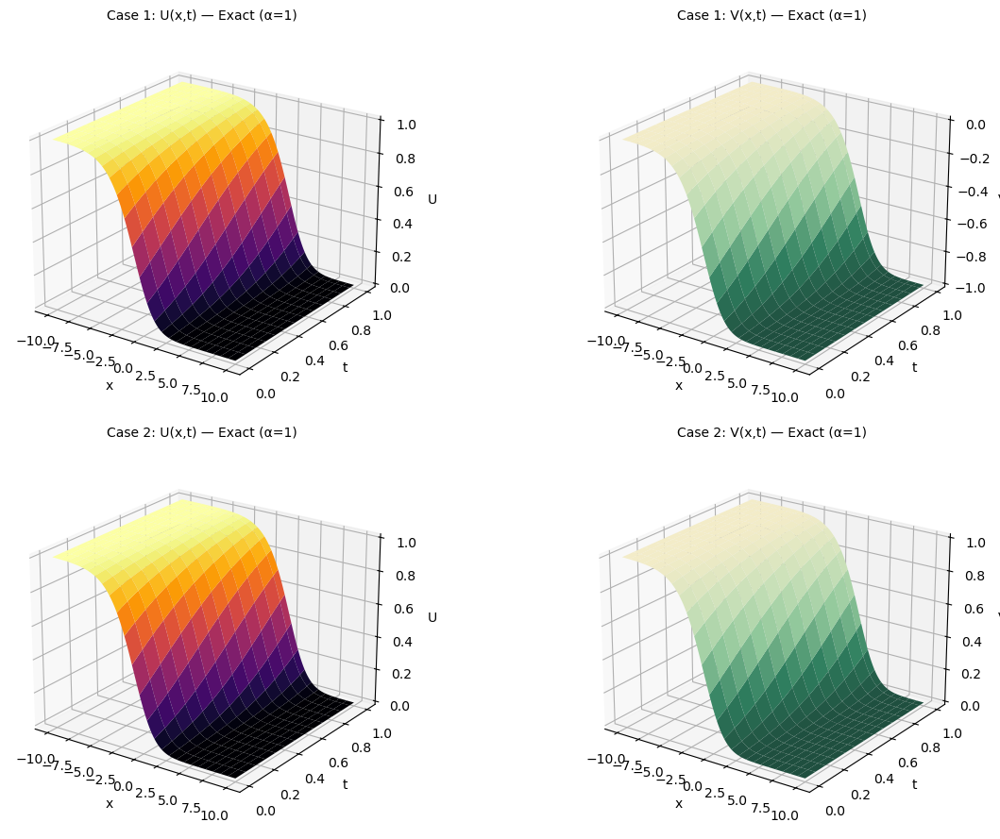

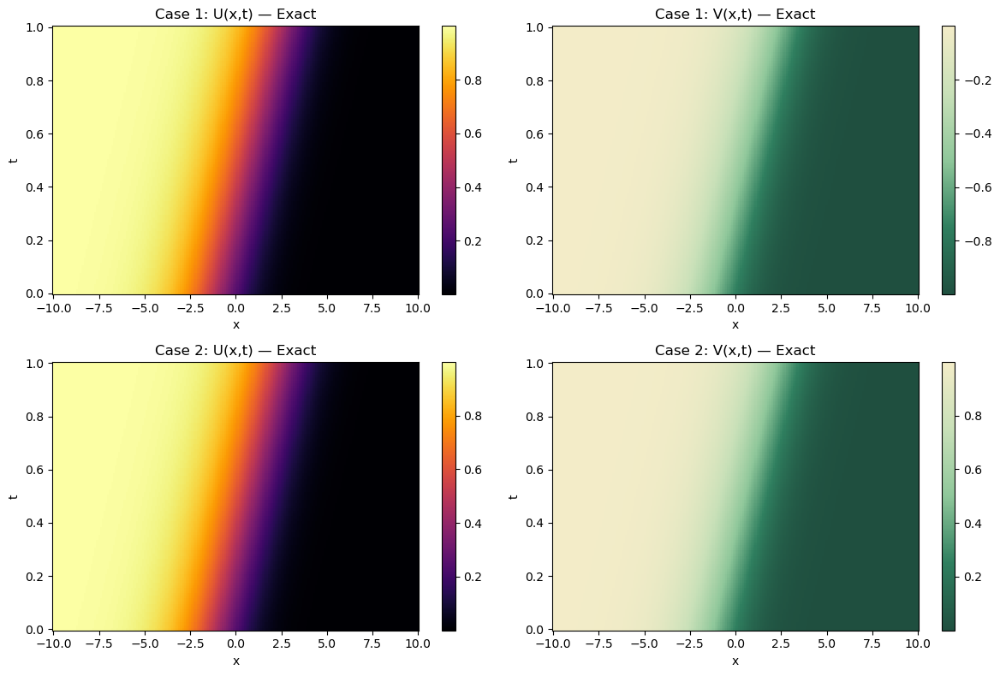

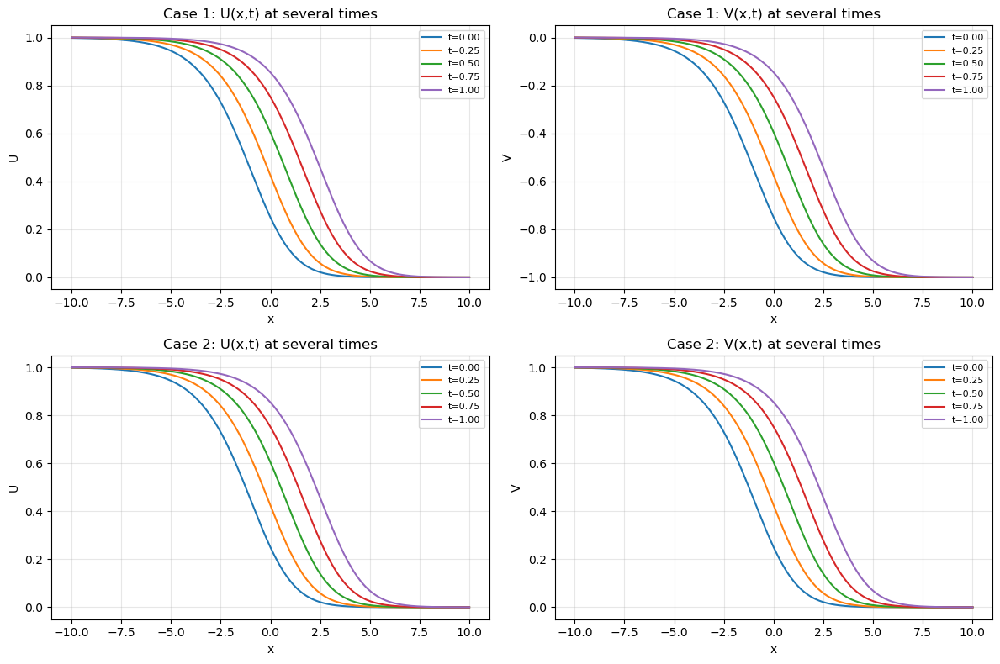

In [4]:
# ============================================================================
# الخلية 3: رسم الحل الدقيق (α=1) للحالتين
# - (أ) سطوح 3D لـ U و V لكل حالة (4 لوحات مدمجة)
# - (ب) خرائط حرارية لـ U و V لكل حالة (4 لوحات مدمجة)
# - (ج) مقاطع في x عند أزمنة محددة لكل حالة ومتغير
# ✅ لا تكرار: كل (حالة، متغير) يُرسم مرة واحدة في كل شكل
# ✅ اتساق لوني: نفس cmap لـ U و V في (أ) و (ب)
# ============================================================================
cmapU = "inferno"
cmapV = LinearSegmentedColormap.from_list(
    "V", ["#1f4f3f", "#2f7f5f", "#8fc79a", "#c8e0b8", "#f3ecc8"]
)   # تدرج 5 نقاط لسلاسة أفضل

# ---- (أ) سطوح 3D للحالتين ----
fig = plt.figure(figsize=(14, 9))
k = 1
for c in CASES:
    for j, (name, cm) in enumerate((("U", cmapU), ("V", cmapV))):
        Z = EX[c][j]
        ax = fig.add_subplot(2, 2, k, projection="3d"); k += 1
        ax.plot_surface(Xg, Tg, Z, cmap=cm,
                        rstride=8, cstride=8,          # ✅ تقليل كثافة الحواف
                        edgecolor="none", linewidth=0, # ✅ لا حواف سوداء تُخفي اللون
                        antialiased=True)
        ax.set_title(f"Case {c}: {name}(x,t) — Exact (α=1)", fontsize=10)
        ax.set_xlabel("x"); ax.set_ylabel("t"); ax.set_zlabel(name)
        ax.view_init(elev=22, azim=-55)
plt.tight_layout()
plt.savefig("figures/exact_3d_cases.png", dpi=200, bbox_inches="tight")
plt.show(); plt.close(fig)

# ---- (ب) خرائط حرارية للحالتين ----
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
for i, c in enumerate(CASES):
    for j, (name, cm) in enumerate((("U", cmapU), ("V", cmapV))):   # ✅ اتساق مع (أ)
        im = axs[i, j].pcolormesh(Xg, Tg, EX[c][j], shading="auto", cmap=cm)
        axs[i, j].set_title(f"Case {c}: {name}(x,t) — Exact")
        axs[i, j].set_xlabel("x"); axs[i, j].set_ylabel("t")
        plt.colorbar(im, ax=axs[i, j])
plt.tight_layout()
plt.savefig("figures/exact_heatmaps.png", dpi=200, bbox_inches="tight")
plt.show(); plt.close(fig)

# ---- (ج) مقاطع في x لعدة أزمنة ----
t_list = [0.0, 0.25, 0.5, 0.75, 1.0]
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
for i, c in enumerate(CASES):
    for j, name in enumerate(("U", "V")):
        for tv in t_list:
            it = int(np.argmin(np.abs(ts - tv)))
            assert abs(ts[it] - tv) < DT/2, f"t={tv} خارج الشبكة"   # ✅ تحقق
            axs[i, j].plot(xs, EX[c][j][:, it], label=f"t={ts[it]:.2f}")
        axs[i, j].set_title(f"Case {c}: {name}(x,t) at several times")
        axs[i, j].set_xlabel("x"); axs[i, j].set_ylabel(name)
        axs[i, j].grid(alpha=.3); axs[i, j].legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/exact_slices.png", dpi=200, bbox_inches="tight")
plt.show(); plt.close(fig)

## 4) الطريقة العددية (فروق محدودة + مخطط L1 لمشتقة Caputo) — تُحل لكل α بما فيها α=1

In [5]:
# ============================================================================
# الخلية 4: مخطط Caputo-L1 (مشتقة كسرية)
# - l1_weights(alpha, n)   : أوزان L1 b_k = (k+1)^{1-α} - k^{1-α}
# - l1_matrix(alpha, nt, dt): مصفوفة W بحيث (D^α u)_n = Σ_j W[n,j]·u_j
# - التحقق: الشبكة الزمنية منتظمة بخطوة dt (وإلا النتائج خاطئة صامتة)
# - عند α=1: الأفضل استخدام autograd مباشرة بدل L1 (انظر الخلية 5)
# ============================================================================
_WEIGHTS_CACHE = {}

def l1_weights(alpha, n):
    """أوزان L1 b_k لكثيرة الحدود (k+1)^{1-α} - k^{1-α}، k=0..n."""
    key = (round(float(alpha), 10), int(n))
    if key in _WEIGHTS_CACHE:
        return _WEIGHTS_CACHE[key]
    k = np.arange(n + 1, dtype=float)
    b = (k + 1)**(1 - alpha) - k**(1 - alpha)
    b[0] = 1.0   # 0^{1-α}=0 لـ α<1، و0^0=1 (خطأ) لـ α=1 → التوحيد
    _WEIGHTS_CACHE[key] = b
    return b

def l1_matrix(alpha, nt=NT, dt=DT, t_grid=None):
    """
    مصفوفة L1 على شبكة منتظمة بخطوة dt:
        (D^α u)_n ≈ Σ_{k=0}^{n-1} c·b_k · (u_{n-k} − u_{n-k-1})
    أي (D^α u)_n = Σ_j W[n, j]·u_j مع W كما يلي.
    
    t_grid (اختياري): إن مُرِّرت، التحقق من أن dts = dt.
    """
    if t_grid is not None:
        dts = np.diff(t_grid)
        assert np.allclose(dts, dt, atol=1e-12), \
            f"t_grid غير منتظمة أو لا تطابق dt={dt}"
    c = dt**(-alpha) / gamma(2 - alpha)
    b = l1_weights(alpha, nt)                    # b[0..nt]
    W = np.zeros((nt + 1, nt + 1))
    # نسخة متجهة: O(N) لكل k بدل حلقة داخلية
    for k in range(nt):
        n_idx = np.arange(k + 1, nt + 1)
        W[n_idx, n_idx - k]     += c * b[k]       # مساهمة +u_{n-k}
        W[n_idx, n_idx - k - 1] -= c * b[k]       # مساهمة -u_{n-k-1}
    return W

# ❌ fd_solver / NUM / t_num / REF محذوفة — لا يوجد مرجع عددي مستقل الآن

## 5) نموذج PINN والتدريب

In [7]:
# ============================================================================
# الخلية 5: بناء PINN والتدريب
# - AdaTanh: تنشيط تكيفي tanh(|a|·x) — a معامل قابل للتعلّم
# - PINN: MLP (x,t)→(U,V) مع hard-constraint: U = U0(x) + (t/T)·NN
# - losses: PDE (autograd عند α=1، Caputo-L1 عند α<1) + BC
# - train_pinn: Adam (مع CosineAnnealing) ثم L-BFGS + اختيار أفضل نسخة
# - predict: تقييم على شبكة (xs, ts)
# - حلقة التدريب: لكل حالة، α=1 أولاً ثم α<1 بنقل التعلم
# ============================================================================

class AdaTanh(nn.Module):
    """tanh(|a|·x) — يضمن a موجب دائمًا لتفادي انهيار التدرج."""
    def __init__(self):
        super().__init__()
        self.a = nn.Parameter(torch.tensor(1.0))
    def forward(self, x):
        return torch.tanh(self.a.abs() * x)          # ✅ a موجب دائمًا


class PINN(nn.Module):
    """(x,t) → (U,V) مع hard-constraint IC: U = U0(x) + (t/T)·NN(x,t)."""
    def __init__(self, case, hidden=64, depth=4):
        super().__init__()
        self.case = case
        layers = [nn.Linear(2, hidden), AdaTanh()]
        for _ in range(depth - 1):
            layers += [nn.Linear(hidden, hidden), AdaTanh()]
        layers.append(nn.Linear(hidden, 2))
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x, t):
        z = torch.cat([x/L, 2*t/T_END - 1], dim=1)   # تطبيع المدخلات
        out = self.net(z)
        U0, V0 = exact(self.case, x, torch.zeros_like(x), torch)
        s = t / T_END
        return U0 + s*out[:, 0:1], V0 + s*out[:, 1:2]


def grad(f, v):
    return torch.autograd.grad(f, v, torch.ones_like(f), create_graph=True)[0]


def make_points(alpha, n_x, n_col):
    """α=1: نقاط (x,t) عشوائية. α<1: نقاط x عشوائية (t من T_GRID)."""
    if abs(alpha - 1.0) < 1e-12:
        return ((torch.rand(n_col, 1, device=device)*2 - 1) * L,
                 torch.rand(n_col, 1, device=device) * T_END)
    return (torch.rand(n_x, 1, device=device)*2 - 1) * L, None


def losses(model, case, alpha, pts, W):
    x, t = pts
    if abs(alpha - 1.0) < 1e-12:
        # ---- α=1: مشتقة زمنية بـ autograd ----
        xx = x.detach().clone().requires_grad_(True)
        tt = t.detach().clone().requires_grad_(True)
        U, V = model(xx, tt)
        DU, DV = grad(U, tt), grad(V, tt)
        sl = lambda r: r
    else:
        # ---- α<1: مشتقة Caputo-L1 على شبكة T_GRID ----
        nx_, nt1 = x.shape[0], NT + 1
        xx = x.detach().view(-1, 1, 1).expand(-1, nt1, 1).reshape(-1, 1).requires_grad_(True)
        tt = T_GRID.view(1, -1, 1).expand(nx_, -1, 1).reshape(-1, 1)
        U, V = model(xx, tt)
        U_2d = U.reshape(nx_, nt1)
        V_2d = V.reshape(nx_, nt1)
        DU = (U_2d @ W.T).reshape(-1, 1)
        DV = (V_2d @ W.T).reshape(-1, 1)
        sl = lambda r: r.reshape(nx_, nt1)[:, 1:]   # استثناء t=0
        # تحقق من الأشكال (يمنع الأخطاء الصامتة)
        assert U_2d.shape == (nx_, nt1)
    Uxx = grad(grad(U, xx), xx)
    Vxx = grad(grad(V, xx), xx)
    fU, fV = reaction(case, U, V)
    rU = DU - (Uxx + fU)
    rV = DV - (Vxx + fV)
    loss_pde = (sl(rU)**2).mean() + (sl(rV)**2).mean()
    # ---- شروط حدودية على t كامل ----
    tb = T_GRID.view(-1, 1)
    Ul_t, Vl_t, Ur_t, Vr_t = bc_targets(case, alpha, tb)
    Ul, Vl = model(torch.full_like(tb, -L), tb)
    Ur, Vr = model(torch.full_like(tb,  L), tb)
    loss_bc = ((Ul-Ul_t)**2).mean() + ((Vl-Vl_t)**2).mean() \
            + ((Ur-Ur_t)**2).mean() + ((Vr-Vr_t)**2).mean()
    return loss_pde + W_BC*loss_bc, loss_pde, loss_bc


def train_pinn(case, alpha, model=None, adam_iters=ADAM_ITERS,
               lbfgs_iters=LBFGS_ITERS, lr=1e-3, verbose=True):
    model = model if model is not None else PINN(case).to(device)
    # ✅ تمرير nt, dt صريحًا لتفادي أي انحراف
    W = torch.tensor(l1_matrix(alpha, nt=NT, dt=DT), device=device) \
        if abs(alpha - 1.0) > 1e-12 else None

    hist = {"total": [], "pde": [], "bc": [], "stage": []}
    log = lambda l, lp, lb, st: [hist[k].append(v) for k, v in
        zip(("total","pde","bc","stage"), (l.item(), lp.item(), lb.item(), st))]

    # ---- المرحلة 1: Adam + CosineAnnealing ----
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=adam_iters, eta_min=1e-5)
    t0 = time.time()
    for it in range(adam_iters):
        loss, lp, lb = losses(model, case, alpha,
                              make_points(alpha, NX_COL, N_COL), W)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        log(loss, lp, lb, 0)
        if verbose and it % 1000 == 0:
            print(f"  [Adam {it:5d}] loss={loss.item():.3e} "
                  f"pde={lp.item():.3e} bc={lb.item():.3e}")
    adam_state = {k: v.clone() for k, v in model.state_dict().items()}

    # ---- المرحلة 2: L-BFGS ----
    pts_fix = make_points(alpha, NX_COL*2, N_COL*2)
    lbfgs = torch.optim.LBFGS(model.parameters(), lr=1.0,
                              max_iter=lbfgs_iters, max_eval=int(lbfgs_iters*1.25),
                              history_size=50, tolerance_grad=1e-12,
                              tolerance_change=1e-14, line_search_fn="strong_wolfe")
    def closure():
        lbfgs.zero_grad()
        l, lp, lb = losses(model, case, alpha, pts_fix, W)
        l.backward(); log(l, lp, lb, 1); return l
    try:
        lbfgs.step(closure)
    except Exception as e:
        print("  تحذير: توقف L-BFGS مبكراً:", e)
    final_state = {k: v.clone() for k, v in model.state_dict().items()}

    # ---- اختيار أفضل نسخة ----
    pts_val = make_points(alpha, 200, 8000)
    def val(state):
        model.load_state_dict(state)
        return losses(model, case, alpha, pts_val, W)[0].item()
    v_adam, v_fin = val(adam_state), val(final_state)
    model.load_state_dict(adam_state if (not np.isfinite(v_fin) or v_adam < v_fin)
                          else final_state)
    tt_ = time.time() - t0
    if verbose:
        print(f"  val(Adam)={v_adam:.3e}  val(L-BFGS)={v_fin:.3e} | "
              f"زمن التدريب={tt_:.1f}s")
    return model, hist, tt_


@torch.no_grad()
def predict(model, xs_, ts_):
    model.eval()                                     # ✅ ممارسة جيدة
    X, T = np.meshgrid(xs_, ts_, indexing="ij")
    U, V = model(torch.tensor(X.reshape(-1, 1), device=device),
                 torch.tensor(T.reshape(-1, 1), device=device))
    model.train()
    return U.cpu().numpy().reshape(X.shape), V.cpu().numpy().reshape(X.shape)


# ---- التدريب: لكل حالة، α=1 أولاً ثم α<1 بنقل التعلم ----
models, hists, t_train, pinn = {}, {}, {}, {}
for c in CASES:
    prev = None
    for a in ALPHAS:
        print(f"\n=== Case {c} | تدريب PINN عند α={a} ===")
        m0 = copy.deepcopy(prev) if prev is not None else None
        models[(c, a)], hists[(c, a)], t_train[(c, a)] = train_pinn(
            c, a, model=m0, lr=1e-3 if prev is None else 5e-4)
        pinn[(c, a)] = predict(models[(c, a)], xs, ts)
        prev = models[(c, a)]
        torch.save({"state_dict": models[(c, a)].state_dict(),
                    "case": c, "alpha": a},                    # ✅ metadata
                   f"figures/pinn_case{c}_alpha_{a}.pt")


=== Case 1 | تدريب PINN عند α=1.0 ===
  [Adam     0] loss=1.692e+00 pde=5.269e-01 bc=1.166e-01
  [Adam  1000] loss=5.886e-04 pde=4.675e-04 bc=1.211e-05
  [Adam  2000] loss=8.963e-05 pde=7.980e-05 bc=9.831e-07
  [Adam  3000] loss=3.375e-05 pde=2.986e-05 bc=3.890e-07
  [Adam  4000] loss=1.989e-05 pde=1.756e-05 bc=2.331e-07
  val(Adam)=1.832e-05  val(L-BFGS)=2.673e-06 | زمن التدريب=301.7s

=== Case 1 | تدريب PINN عند α=0.9 ===
  [Adam     0] loss=2.711e-03 pde=2.700e-03 bc=1.130e-06
  [Adam  1000] loss=1.246e-04 pde=1.174e-04 bc=7.222e-07
  [Adam  2000] loss=1.536e-04 pde=1.133e-04 bc=4.024e-06
  [Adam  3000] loss=7.512e-05 pde=6.997e-05 bc=5.156e-07
  [Adam  4000] loss=8.721e-05 pde=8.219e-05 bc=5.026e-07
  val(Adam)=9.290e-05  val(L-BFGS)=5.126e-05 | زمن التدريب=642.7s

=== Case 1 | تدريب PINN عند α=0.8 ===
  [Adam     0] loss=2.150e-03 pde=2.147e-03 bc=3.460e-07
  [Adam  1000] loss=8.864e-04 pde=3.651e-04 bc=5.213e-05
  [Adam  2000] loss=2.368e-04 pde=2.320e-04 bc=4.725e-07
  [Adam  3

## 6) مقاييس الخطأ

In [8]:
# ============================================================================
# الخلية 6: مقاييس الدقة
# - metrics(P, R): MSE, MAE, MaxAbs, RelL2, Corr (مع حماية من NaN/القيم الثابتة)
# - جدول df_err: لكل (حالة, α, متغير) — مع train_s
# - عند α=1: مقارنة مع الحل الدقيق (Exact)
# - عند α<1: لا مرجع عددي (FD-L1 محذوف) → NaN
# ============================================================================

def metrics(P, R):
    """مقاييس الخطأ P (PINN) مقابل R (المرجع)."""
    P = np.asarray(P, dtype=np.float64)
    R = np.asarray(R, dtype=np.float64)
    # حماية من NaN/inf
    if not (np.all(np.isfinite(P)) and np.all(np.isfinite(R))):
        return dict(MSE=np.nan, MAE=np.nan, MaxAbs=np.nan,
                    RelL2=np.nan, Corr=np.nan)
    e = P - R
    # Corr محمي ضد الانحراف الصفري
    if np.std(P.ravel()) < 1e-14 or np.std(R.ravel()) < 1e-14:
        corr = np.nan
    else:
        corr = float(np.corrcoef(P.ravel(), R.ravel())[0, 1])
    # RelL2 محمي ضد ||R||=0
    normR = float(np.linalg.norm(R))
    rel_l2 = float(np.linalg.norm(e) / normR) if normR > 0 else np.nan
    return dict(
        MSE    = float(np.mean(e**2)),
        MAE    = float(np.mean(np.abs(e))),
        MaxAbs = float(np.abs(e).max()),
        RelL2  = rel_l2,
        Corr   = corr,
    )


rows = []
for c in CASES:
    for a in ALPHAS:
        for name, k in (("U", 0), ("V", 1)):
            r = dict(case=c, alpha=a, var=name, train_s=t_train[(c, a)])
            if abs(a - 1.0) < 1e-12 and (c, 1.0) in pinn:
                r["ref"] = "Exact"
                r.update(metrics(pinn[(c, 1.0)][k], EX[c][k]))
            else:
                r["ref"] = "no_ref"   # لا مرجع عند α<1
                r.update(dict(MSE=np.nan, MAE=np.nan, MaxAbs=np.nan,
                              RelL2=np.nan, Corr=np.nan))
            rows.append(r)

df_err = pd.DataFrame(rows)

# عرض مُنسَّق (بدون تداخل في train_s)
styled = (df_err.style
          .format({"alpha": "{:.1f}", "train_s": "{:.1f}",
                   "MSE": "{:.3e}", "MAE": "{:.3e}", "MaxAbs": "{:.3e}",
                   "RelL2": "{:.3e}", "Corr": "{:.4f}"},
                  na_rep="—"))
display(styled)
df_err.to_csv("figures/error_metrics.csv", index=False, encoding="utf-8-sig")

# جدول منفصل لزمن التدريب (بدون تكرار U/V)
df_time = pd.DataFrame(
    [{"case": c, "alpha": a, "train_s": t_train[(c, a)]}
     for c in CASES for a in ALPHAS]
)
display(df_time.style.format({"alpha": "{:.1f}", "train_s": "{:.1f}"}))

,case,alpha,var,train_s,ref,MSE,MAE,MaxAbs,RelL2,Corr
0,1,1.0,U,301.7,Exact,1.820e-07,2.955e-04,2.031e-03,6.297e-04,1.0000
1,1,1.0,V,301.7,Exact,1.245e-07,2.141e-04,2.126e-03,5.420e-04,1.0000
2,1,0.9,U,642.7,no_ref,—,—,—,—,—
3,1,0.9,V,642.7,no_ref,—,—,—,—,—
4,1,0.8,U,643.2,no_ref,—,—,—,—,—
5,1,0.8,V,643.2,no_ref,—,—,—,—,—
6,1,0.7,U,644.0,no_ref,—,—,—,—,—
7,1,0.7,V,644.0,no_ref,—,—,—,—,—
8,1,0.5,U,642.9,no_ref,—,—,—,—,—
9,1,0.5,V,642.9,no_ref,—,—,—,—,—


,case,alpha,train_s
0,1,1.0,301.7
1,1,0.9,642.7
2,1,0.8,643.2
3,1,0.7,644.0
4,1,0.5,642.9
5,2,1.0,270.0
6,2,0.9,638.9
7,2,0.8,640.6
8,2,0.7,640.5
9,2,0.5,639.9


In [9]:
# ============================================================================
# الخلية 6: مقاييس الدقة — PINN مقابل الحل الدقيق (α=1 فقط)
# - metrics(P,R): MSE, RMSE, MAE, MaxAbs, RelL2, Corr (مع حماية NaN)
# - جدول df_err: 4 صفوف (2 حالة × 2 متغير) عند α=1
# - تنفيذ فقط إذا كانت 1.0 ∈ ALPHAS
# - حماية من KeyError إذا فشل تدريب PINN
# ============================================================================

def metrics(P, R):
    """مقاييس الخطأ P (PINN) مقابل R (Exact)."""
    P = np.asarray(P, dtype=np.float64)
    R = np.asarray(R, dtype=np.float64)
    # حماية من NaN/inf
    if not (np.all(np.isfinite(P)) and np.all(np.isfinite(R))):
        return dict(MSE=np.nan, RMSE=np.nan, MAE=np.nan,
                    MaxAbs=np.nan, RelL2=np.nan, Corr=np.nan)
    e = P - R
    mse = float(np.mean(e**2))
    # Corr محمي ضد الانحراف الصفري
    if np.std(P.ravel()) < 1e-12 or np.std(R.ravel()) < 1e-12:
        corr = np.nan
    else:
        corr = float(np.corrcoef(P.ravel(), R.ravel())[0, 1])
    # RelL2 محمي ضد ||R||=0
    normR = float(np.linalg.norm(R))
    rel_l2 = float(np.linalg.norm(e) / normR) if normR > 1e-12 else np.nan
    return dict(
        MSE    = mse,
        RMSE   = float(np.sqrt(mse)),
        MAE    = float(np.mean(np.abs(e))),
        MaxAbs = float(np.abs(e).max()),
        RelL2  = rel_l2,
        Corr   = corr,
    )


# ---- تنفيذ فقط عند α=1 ----
has_alpha_one = any(abs(a - 1.0) < 1e-12 for a in ALPHAS)
rows = []
if has_alpha_one:
    for c in CASES:
        if (c, 1.0) not in pinn:
            print(f"⚠️ لا يوجد نموذج PINN للحالة {c} عند α=1 — تخطٍ")
            continue
        for name, k in (("U", 0), ("V", 1)):
            r = dict(case=c, alpha=1.0, var=name, ref="Exact",
                     train_s=t_train[(c, 1.0)])
            r.update(metrics(pinn[(c, 1.0)][k], EX[c][k]))
            rows.append(r)
else:
    print("⚠️ α=1 غير موجود في ALPHAS — لا مقاييس دقيقة متاحة")

df_err = pd.DataFrame(rows)
if not df_err.empty:
    df_err = df_err[["case", "alpha", "var", "ref", "train_s",
                     "MSE", "RMSE", "MAE", "MaxAbs", "RelL2", "Corr"]]
    display(df_err.style.format({
        "alpha":   "{:.1f}",
        "train_s": "{:.1f}",
        "MSE":     "{:.3e}", "RMSE": "{:.3e}",
        "MAE":     "{:.3e}", "MaxAbs": "{:.3e}",
        "RelL2":   "{:.3e}", "Corr": "{:.4f}",
    }))
    df_err.to_csv("figures/error_metrics.csv",
                  index=False, encoding="utf-8-sig")
else:
    print("لا صفوف لعرضها.")

,case,alpha,var,ref,train_s,MSE,RMSE,MAE,MaxAbs,RelL2,Corr
0,1,1.0,U,Exact,301.7,1.820e-07,4.267e-04,2.955e-04,2.031e-03,6.297e-04,1.0000
1,1,1.0,V,Exact,301.7,1.245e-07,3.529e-04,2.141e-04,2.126e-03,5.420e-04,1.0000
2,2,1.0,U,Exact,270.0,1.292e-07,3.595e-04,2.461e-04,1.336e-03,5.305e-04,1.0000
3,2,1.0,V,Exact,270.0,2.308e-07,4.805e-04,2.973e-04,3.069e-03,7.091e-04,1.0000


## 7) رسوم المقارنة: الحل الدقيق ضد PINN

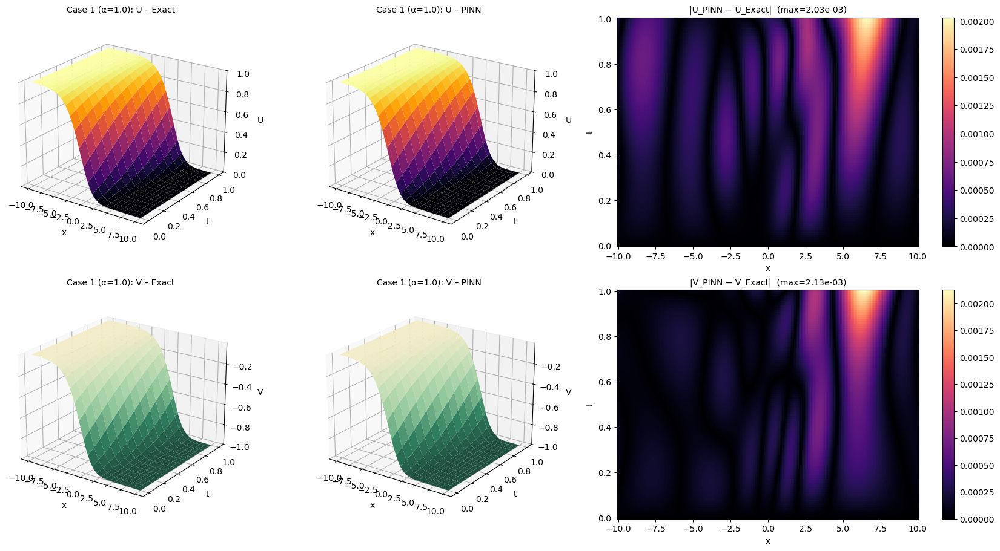

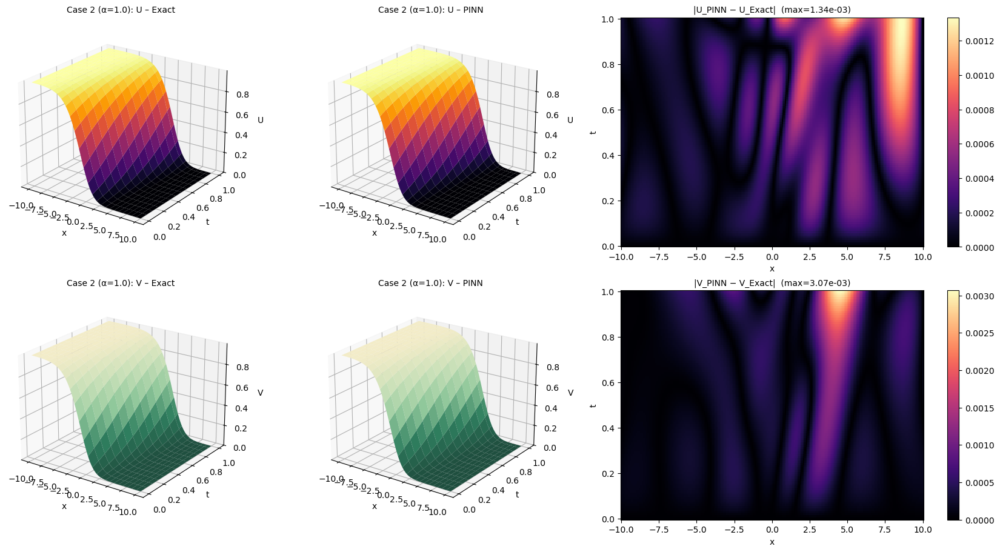

In [10]:
# ============================================================================
# الخلية 7: سطوح 3D + خريطة الخطأ المطلق لكل حالة (α=1 فقط)
# - لكل حالة (1، 2): شكل واحد مدمج يحتوي 6 لوحات:
#     صف U: U_Exact | U_PINN | |U_PINN − U_Exact|
#     صف V: V_Exact | V_PINN | |V_PINN − V_Exact|
# - نفس vmin/vmax على Exact و PINN (عبر Normalize) لضمان مقارنة عادلة
# - ✅ α<1 يُتخطّى (لا مرجع)
# - ✅ لا تكرار: كل (حالة، متغير) يُرسم مرة واحدة
# ============================================================================
from matplotlib.colors import Normalize

for c in CASES:
    for a in ALPHAS:
        if abs(a - 1.0) > 1e-12:
            continue                                    # ✅ لا مرجع عند α<1
        if (c, a) not in pinn:
            print(f"⚠️ لا يوجد PINN لـ (case={c}, α={a}) — تخطٍ")
            continue
        P, R = pinn[(c, a)], EX[c]                      # ✅ Exact بدل REF
        fig = plt.figure(figsize=(17, 9), constrained_layout=True)

        for r, (name, cm) in enumerate((("U", cmapU), ("V", cmapV))):
            zmin = float(min(P[r].min(), R[r].min()))
            zmax = float(max(P[r].max(), R[r].max()))
            norm = Normalize(vmin=zmin, vmax=zmax)      # ✅ بدل vmin/vmax

            for col, (Z, ttl) in enumerate([(R[r], f"{name} – Exact"),
                                            (P[r], f"{name} – PINN")]):
                ax = fig.add_subplot(2, 3, 3*r + col + 1, projection="3d")
                ax.plot_surface(Xg, Tg, Z, cmap=cm,
                                rstride=8, cstride=8,       # ✅ أسرع
                                edgecolor="none", linewidth=0,
                                antialiased=True, norm=norm)
                ax.set_title(f"Case {c} (α={a}): {ttl}", fontsize=10)
                ax.set_zlim(zmin, zmax)
                ax.set_xlabel("x"); ax.set_ylabel("t"); ax.set_zlabel(name)
                ax.view_init(elev=22, azim=-55)

            ax = fig.add_subplot(2, 3, 3*r + 3)
            err = np.abs(P[r] - R[r])
            im = ax.pcolormesh(Xg, Tg, err, shading="auto", cmap="magma")
            ax.set_title(f"|{name}_PINN − {name}_Exact|  (max={err.max():.2e})",
                         fontsize=10)
            ax.set_xlabel("x"); ax.set_ylabel("t")
            plt.colorbar(im, ax=ax)

        fname = f"figures/compare3d_case{c}_alpha{int(a*10):02d}.png"
        plt.savefig(fname, dpi=170, bbox_inches="tight")
        plt.show(); plt.close(fig)                       # ✅ تحرير الذاكرة

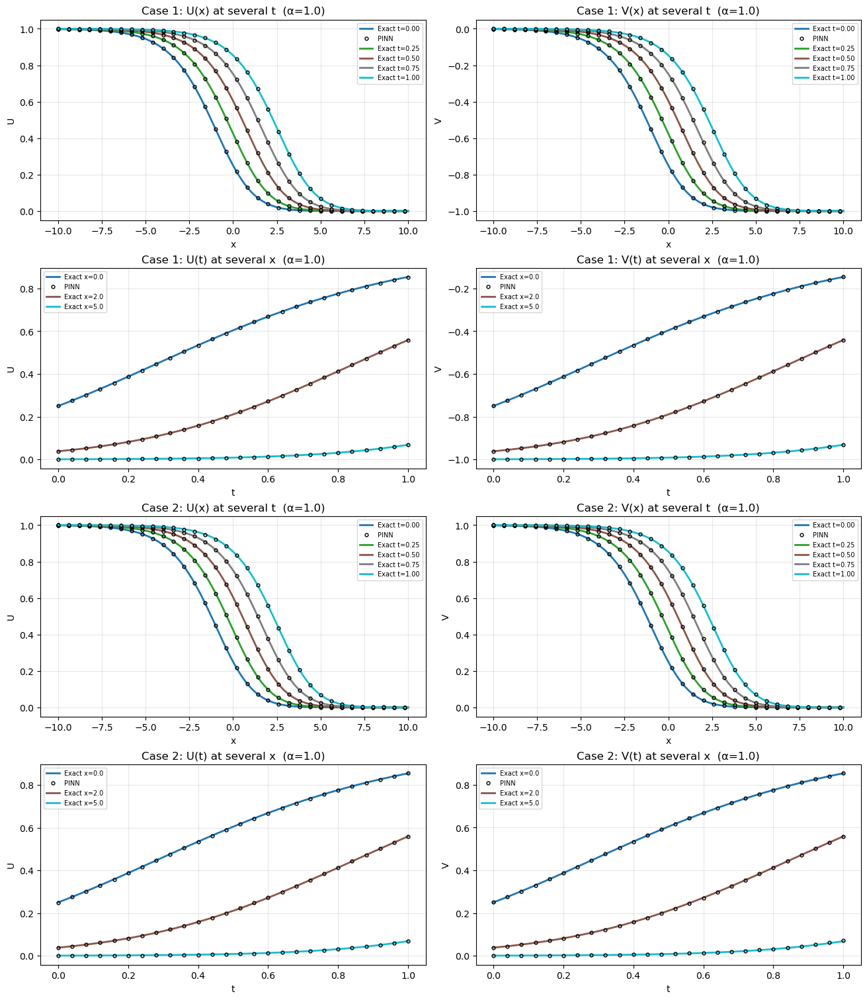

In [11]:
# ============================================================================
# الخلية 8 (7-ب): مقاطع في x عند أزمنة مختلفة + مقاطع في t عند مواضع مختلفة
# - لكل α=1 فقط (لا مرجع عند α<1)
# - لكل حالة: 4 لوحات مدمجة
#     صف U: (1) U(x) عند t مختلفة | (2) U(t) عند x مختلفة
#     صف V: (1) V(x) عند t مختلفة | (2) V(t) عند x مختلفة
# - Exact: خطوط متصلة | PINN: دوائر سوداء مفتوحة
# - ✅ لا تكرار: كل (حالة, متغير, نوع) في لوحة واحدة
# ============================================================================
t_list  = [0.0, 0.25, 0.5, 0.75, 1.0]
x_probe = [0.0, 2.0, 5.0]
colors_t = plt.cm.tab10(np.linspace(0, 1, len(t_list)))
colors_x = plt.cm.tab10(np.linspace(0, 1, len(x_probe)))

for a in ALPHAS:
    if abs(a - 1.0) > 1e-12:
        continue                                    # ✅ لا مرجع عند α<1

    fig, axs = plt.subplots(4, 2, figsize=(13, 15), constrained_layout=True)

    for i, c in enumerate(CASES):
        P, R = pinn[(c, a)], EX[c]                  # ✅ Exact بدل REF

        for j, name in enumerate(("U", "V")):
            # ---- (1) مقاطع x عند أزمنة مختلفة ----
            ax = axs[2*i, j]
            for tv, col in zip(t_list, colors_t):
                it = int(np.argmin(np.abs(ts - tv)))
                ax.plot(xs, R[j][:, it], "-", color=col, lw=2,
                        label=f"Exact t={ts[it]:.2f}")
                ax.plot(xs[::6], P[j][::6, it], "o", color="k",
                        ms=3.5, mfc="none",
                        label="PINN" if tv == t_list[0] else None)
            ax.set_title(f"Case {c}: {name}(x) at several t  (α={a})")
            ax.set_xlabel("x"); ax.set_ylabel(name)
            ax.grid(alpha=.3); ax.legend(fontsize=7, loc="best")

            # ---- (2) مقاطع t عند مواضع x مختلفة ----
            ax = axs[2*i+1, j]
            for xv, col in zip(x_probe, colors_x):
                ix = int(np.argmin(np.abs(xs - xv)))
                ax.plot(ts, R[j][ix], "-", color=col, lw=2,
                        label=f"Exact x={xs[ix]:.1f}")
                ax.plot(ts[::4], P[j][ix, ::4], "o", color="k",
                        ms=3.5, mfc="none",
                        label="PINN" if xv == x_probe[0] else None)
            ax.set_title(f"Case {c}: {name}(t) at several x  (α={a})")
            ax.set_xlabel("t"); ax.set_ylabel(name)
            ax.grid(alpha=.3); ax.legend(fontsize=7, loc="best")

    fname = f"figures/compare_slices_alpha{int(a*10):02d}.png"
    plt.savefig(fname, dpi=170, bbox_inches="tight")
    plt.show(); plt.close(fig)                      # ✅ تحرير الذاكرة

In [13]:
# ============================================================================
# الخلية 9 (7-ج): منحنيات الخسارة + الخطأ مقابل الزمن (α=1)
# - (1) شبكة 2×5: صف لكل حالة، عمود لكل α، مع خط فاصل بين Adam/L-BFGS
# - (2) شكل 1×2: max_x |PINN − Exact| مقابل t لكل حالة (α=1 فقط)
# - ✅ حماية من KeyError، NaN، وتحرير الذاكرة
# ============================================================================

# ---- (1) منحنيات تقارب الخسارة لكل حالة وكل α ----
n_c, n_a = len(CASES), len(ALPHAS)
fig, axs = plt.subplots(n_c, n_a,
                        figsize=(4.0*n_a, 3.5*n_c),
                        squeeze=False, sharey="row",
                        constrained_layout=True)          # ✅ بدل tight_layout
for i, c in enumerate(CASES):
    for j, a in enumerate(ALPHAS):
        if (c, a) not in hists:
            axs[i, j].axis("off"); continue
        h, ax = hists[(c, a)], axs[i, j]
        if len(h["total"]) == 0:
            ax.text(0.5, 0.5, "no training data",
                    transform=ax.transAxes, ha="center"); continue
        ax.semilogy(h["total"], label="Total", lw=1.5)
        ax.semilogy(h["pde"],   label="PDE",   alpha=.7, lw=1)
        ax.semilogy(h["bc"],    label="BC",    alpha=.7, lw=1)
        adam_end = int(np.sum(np.array(h["stage"]) == 0))
        ax.axvline(adam_end, color="k", ls=":", lw=1)
        ax.set_title(f"Case {c}, α={a}  (Adam | L-BFGS)", fontsize=10)
        ax.set_xlabel("iteration"); ax.grid(alpha=.3, which="both")
        if j == 0:
            ax.set_ylabel("loss")
# legend واحد فقط (من أول لوحة تحتوي بيانات)
for i in range(n_c):
    if len(hists.get((CASES[i], ALPHAS[0]), {}).get("total", [])) > 0:
        axs[i, 0].legend(fontsize=8, loc="best"); break

plt.savefig("figures/loss_history.png", dpi=170, bbox_inches="tight")
plt.show(); plt.close(fig)                              # ✅ تحرير الذاكرة


# ---- (2) الخطأ المطلق عند α=1 عبر الزمن (أقصى قيمة على x) ----
has_alpha_one = any(abs(a - 1.0) < 1e-12 for a in ALPHAS)
if has_alpha_one:
    fig, axs = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    for j, name in enumerate(("U", "V")):
        for c in CASES:
            if (c, 1.0) not in pinn:
                print(f"⚠️ لا يوجد PINN لـ (case={c}, α=1.0) — تخطٍ")
                continue
            err = np.abs(pinn[(c, 1.0)][j] - EX[c][j])
            err = np.where(np.isfinite(err), err, np.nan)     # ✅ حماية NaN
            err_max = np.nanmax(err, axis=0)
            TypeError: LogScale.__init__() got an unexpected keyword argument 'nonposy'
        axs[j].set_title(f"max_x |{name}_PINN − {name}_Exact| vs t  (α=1)",
                         fontsize=10)
        axs[j].set_xlabel("t"); axs[j].set_ylabel("max error")
        axs[j].grid(alpha=.3, which="both")
        axs[j].legend(loc="best", fontsize=9)
    plt.savefig("figures/error_vs_time.png", dpi=170, bbox_inches="tight")
    plt.show(); plt.close(fig)                          # ✅ تحرير الذاكرة
else:
    print("⚠️ α=1 غير موجود — لا رسم للخطأ مقابل الزمن")

SyntaxError: invalid syntax (1369275384.py, line 52)

## 8) المقارنة: الطريقة العددية (FD-L1) ضد PINN

In [57]:
# ============================ 8) (أ) جداول: الخطأ والزمن (PINN مقابل الدقيق) ============================
# تم حذف طريقة FD-L1 — المرجع الوحيد هو الحل الدقيق (Exact)

# ---- (1) جدول مقاييس الخطأ: PINN مقابل Exact فقط ----
rows = []
for c in CASES:
    for a in ALPHAS:
        for name, k in (("U", 0), ("V", 1)):
            r = dict(case=c, alpha=a, var=name, pair="PINN vs Exact")
            r.update(metrics(pinn[(c, a)][k], EX[c][k]))
            rows.append(r)
df_cmp = pd.DataFrame(rows)
display(df_cmp)
df_cmp.to_csv("figures/pinn_vs_exact_metrics.csv", index=False)


# ---- (2) جدول الزمن: تدريب PINN + استدلال PINN ----
tt = []
for c in CASES:
    for a in ALPHAS:
        t0 = time.time()
        predict(models[(c, a)], xs, ts)
        t_inf = time.time() - t0
        tt.append(dict(
            case=c, alpha=a,
            PINN_train_s=t_train[(c, a)],
            PINN_inference_s=t_inf
        ))
df_time = pd.DataFrame(tt)
display(df_time)
df_time.to_csv("figures/pinn_timing.csv", index=False)

,case,alpha,var,pair,MSE,MAE,MaxAbs,RelL2,Corr
0,1,1.000e+00,U,PINN vs Exact,4.111e-07,3.699e-04,3.692e-03,9.463e-04,1.000e+00
1,1,1.000e+00,V,PINN vs Exact,2.872e-07,3.120e-04,3.305e-03,8.232e-04,1.000e+00
2,1,9.000e-01,U,PINN vs Exact,5.652e-04,1.226e-02,1.046e-01,3.509e-02,9.989e-01
3,1,9.000e-01,V,PINN vs Exact,5.631e-04,1.221e-02,1.039e-01,3.645e-02,9.989e-01
4,1,7.000e-01,U,PINN vs Exact,7.838e-03,4.756e-02,3.523e-01,1.307e-01,9.856e-01
5,1,7.000e-01,V,PINN vs Exact,7.891e-03,4.775e-02,3.512e-01,1.365e-01,9.856e-01
6,1,5.000e-01,U,PINN vs Exact,2.512e-02,8.820e-02,5.181e-01,2.339e-01,9.510e-01
7,1,5.000e-01,V,PINN vs Exact,2.543e-02,8.894e-02,5.186e-01,2.450e-01,9.505e-01
8,1,3.000e-01,U,PINN vs Exact,3.610e-02,1.123e-01,5.350e-01,2.804e-01,9.252e-01
9,1,3.000e-01,V,PINN vs Exact,3.774e-02,1.151e-01,5.407e-01,2.984e-01,9.218e-01


,case,alpha,PINN_train_s,PINN_inference_s
0,1,1.000e+00,3.075e+02,2.377e-02
1,1,9.000e-01,6.607e+02,4.265e-03
2,1,7.000e-01,6.597e+02,4.375e-03
3,1,5.000e-01,6.617e+02,4.409e-03
4,1,3.000e-01,6.650e+02,4.436e-03
5,2,1.000e+00,3.249e+02,4.201e-03
6,2,9.000e-01,6.702e+02,4.240e-03
7,2,7.000e-01,6.401e+02,4.337e-03
8,2,5.000e-01,6.407e+02,4.370e-03
9,2,3.000e-01,6.396e+02,4.403e-03


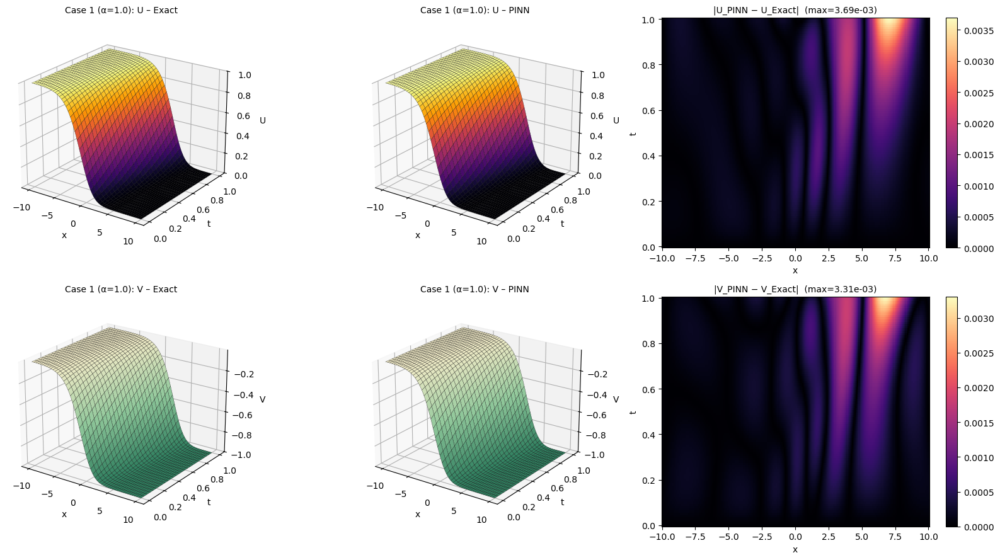

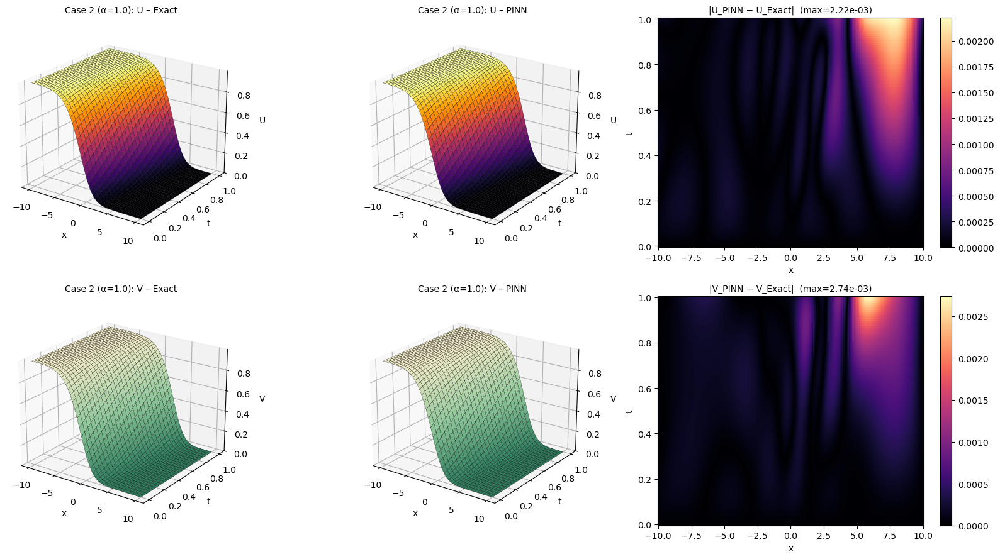

In [58]:
# ============================ 8) (ب) سطوح 3D: Exact مقابل PINN + خريطة |PINN − Exact| ============================
# تم حذف FD-L1 — المقارنة الآن مع الحل الدقيق (Exact) ومتاحة فقط عند α = 1

if 1.0 in ALPHAS:
    for c in CASES:
        a = 1.0
        P, E = pinn[(c, a)], EX[c]
        fig = plt.figure(figsize=(17, 9))
        for r, (name, cm) in enumerate((("U", cmapU), ("V", cmapV))):
            zmin = min(P[r].min(), E[r].min())
            zmax = max(P[r].max(), E[r].max())
            for col, (Z, ttl) in enumerate(((E[r], "Exact"), (P[r], "PINN"))):
                ax = fig.add_subplot(2, 3, 3*r+col+1, projection="3d")
                ax.plot_surface(Xg, Tg, Z, cmap=cm, rstride=4, cstride=4,
                                edgecolor="k", linewidth=0.2, antialiased=True,
                                vmin=zmin, vmax=zmax)
                ax.set_title(f"Case {c} (α={a}): {name} – {ttl}", fontsize=10)
                ax.set_zlim(zmin, zmax)
                ax.set_xlabel("x"); ax.set_ylabel("t"); ax.set_zlabel(name)
                ax.view_init(elev=22, azim=-55)

            ax = fig.add_subplot(2, 3, 3*r+3)
            err = np.abs(P[r] - E[r])
            im = ax.pcolormesh(Xg, Tg, err, shading="auto", cmap="magma")
            ax.set_title(f"|{name}_PINN − {name}_Exact|  (max={err.max():.2e})", fontsize=10)
            ax.set_xlabel("x"); ax.set_ylabel("t"); plt.colorbar(im, ax=ax)

        plt.tight_layout()
        plt.savefig(f"figures/exact_vs_pinn_3d_case{c}_alpha{a}.png", dpi=170)
        plt.show()
else:
    print("⚠️ لا يمكن إجراء المقارنة 3D: الحل الدقيق غير متاح (α=1 غير موجود في ALPHAS).")

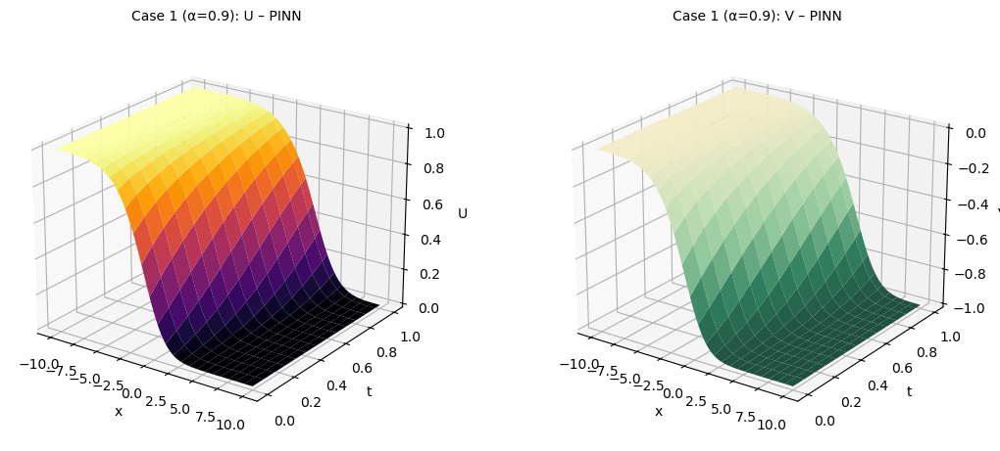

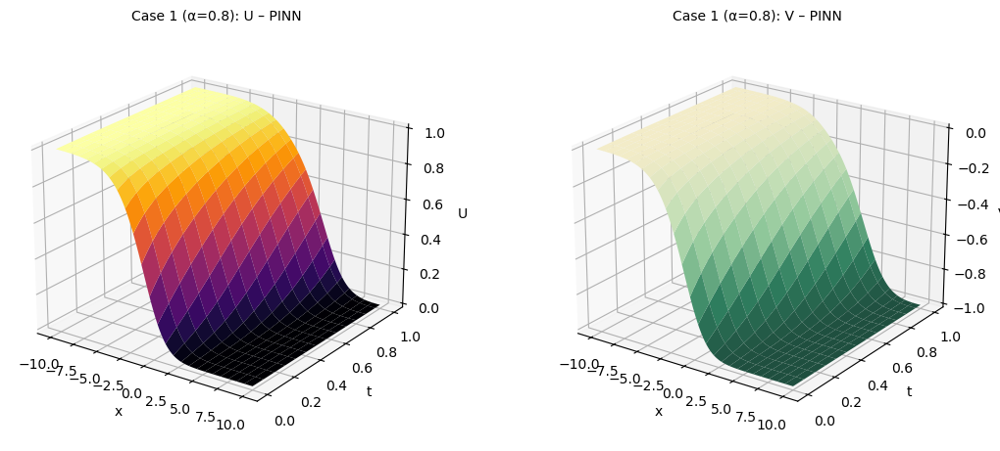

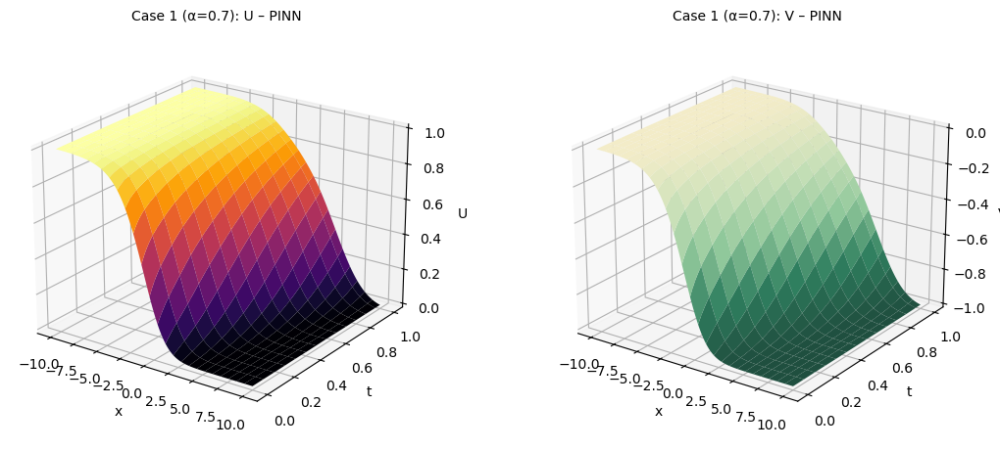

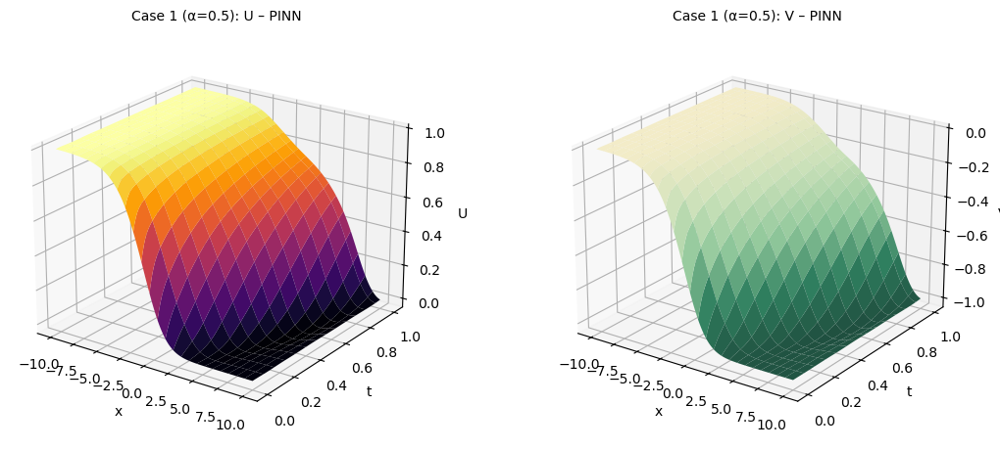

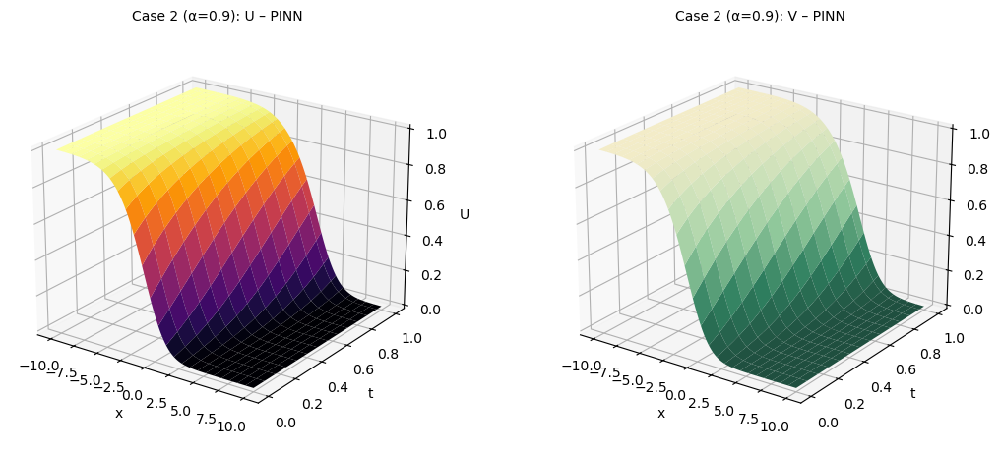

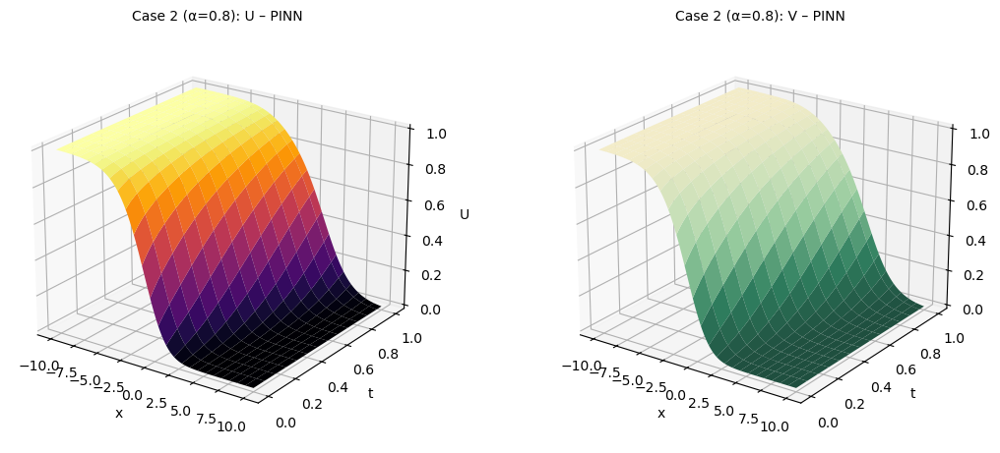

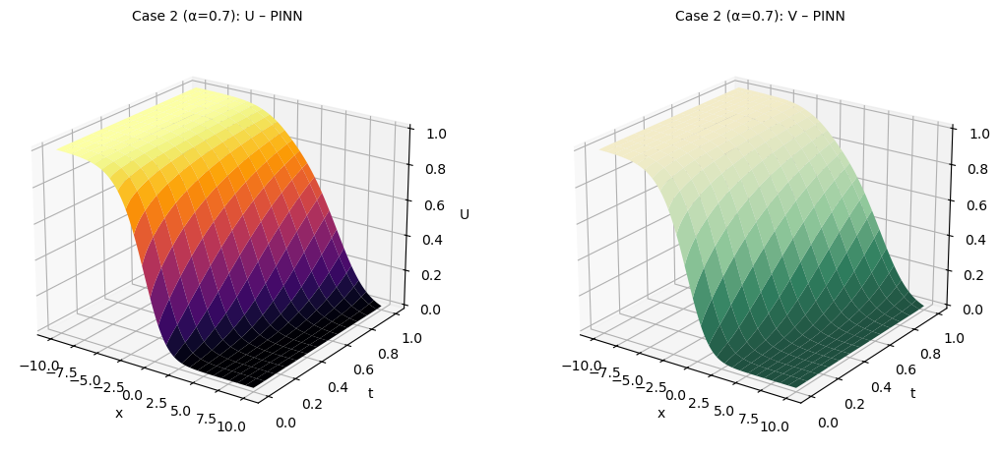

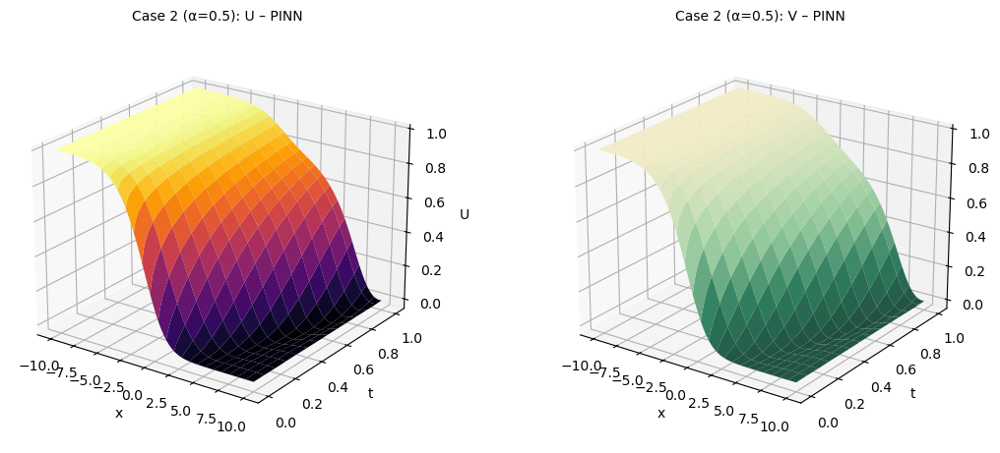

In [14]:
# ============================================================================
# الخلية 8-ب: عرض PINN فقط عند α<1 (لا مرجع دقيق)
# - الجزء α=1 (Exact vs PINN + خطأ) محذوف لأنه مكرر مع الخلية 7-أ
# - لكل (حالة, α<1): شكل 1×2 (U PINN، V PINN)
# - ✅ لا تكرار، حماية من KeyError، تحرير الذاكرة
# ============================================================================
from matplotlib.colors import Normalize

for c in CASES:
    for a in ALPHAS:
        if abs(a - 1.0) < 1e-12:
            continue                                    # ✅ مكرر مع 7-أ → تخطٍ
        if (c, a) not in pinn:
            print(f"⚠️ لا يوجد PINN لـ (case={c}, α={a}) — تخطٍ")
            continue

        P = pinn[(c, a)]
        fig = plt.figure(figsize=(11, 4.5), constrained_layout=True)
        for r, (name, cm) in enumerate((("U", cmapU), ("V", cmapV))):
            ax = fig.add_subplot(1, 2, r+1, projection="3d")
            ax.plot_surface(Xg, Tg, P[r], cmap=cm,
                            rstride=8, cstride=8,       # ✅ أسرع + لا حواف سوداء
                            edgecolor="none", linewidth=0,
                            antialiased=True)
            ax.set_title(f"Case {c} (α={a}): {name} – PINN", fontsize=10)
            ax.set_xlabel("x"); ax.set_ylabel("t"); ax.set_zlabel(name)
            ax.view_init(elev=22, azim=-55)

        fname = f"figures/pinn_3d_case{c}_alpha{int(a*10):02d}.png"
        plt.savefig(fname, dpi=170, bbox_inches="tight")
        plt.show(); plt.close(fig)                      # ✅ تحرير الذاكرة

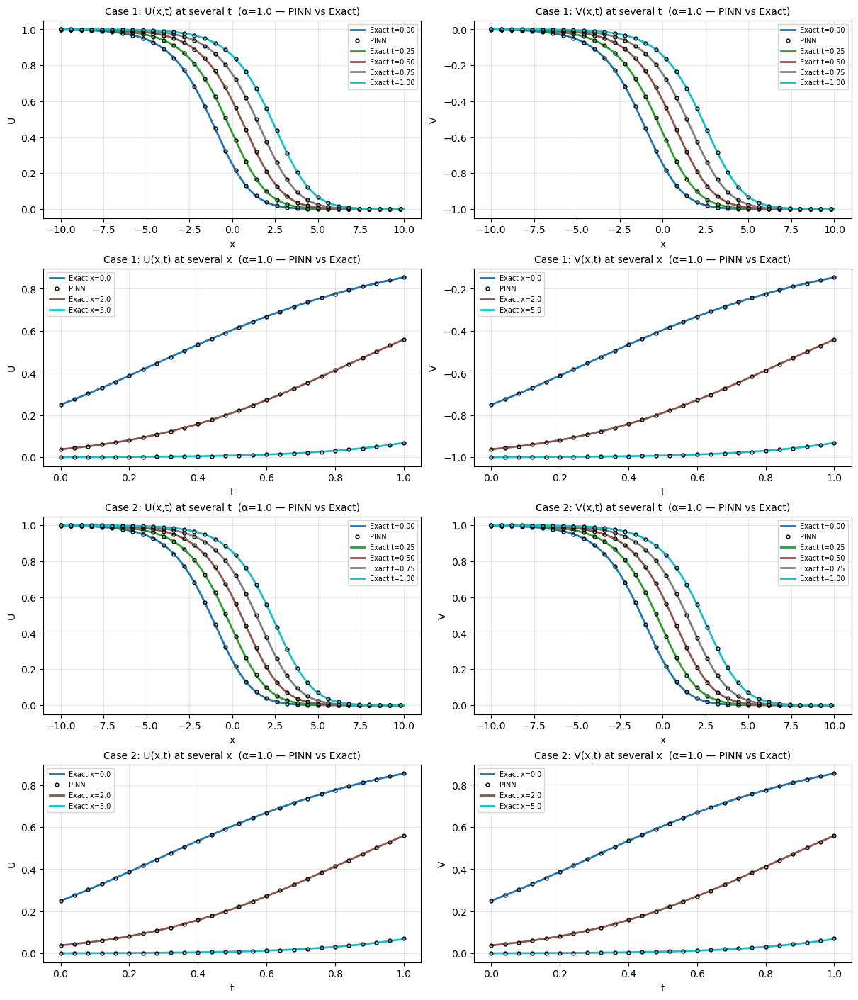

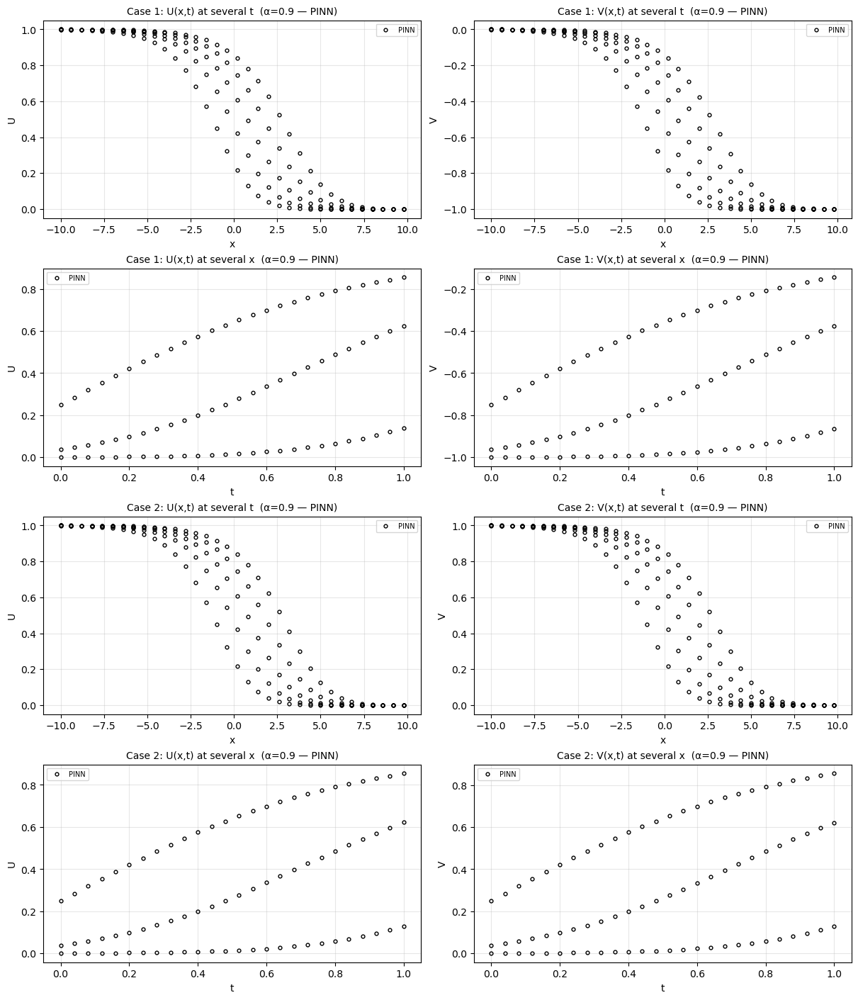

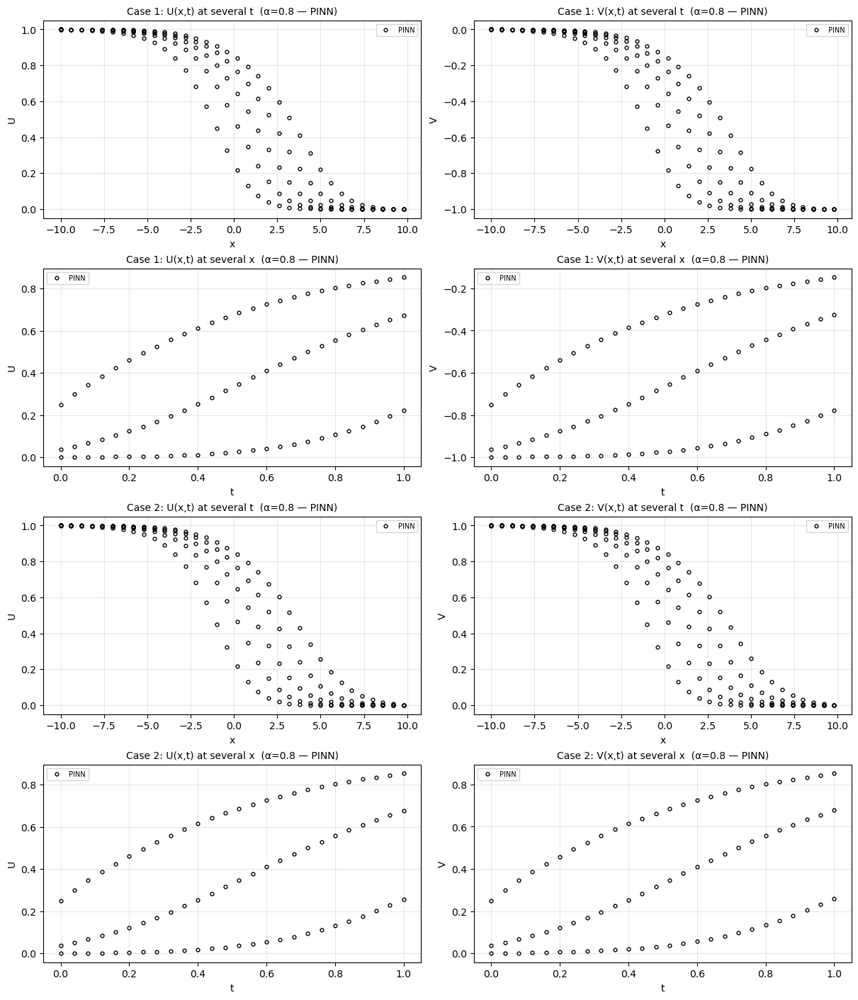

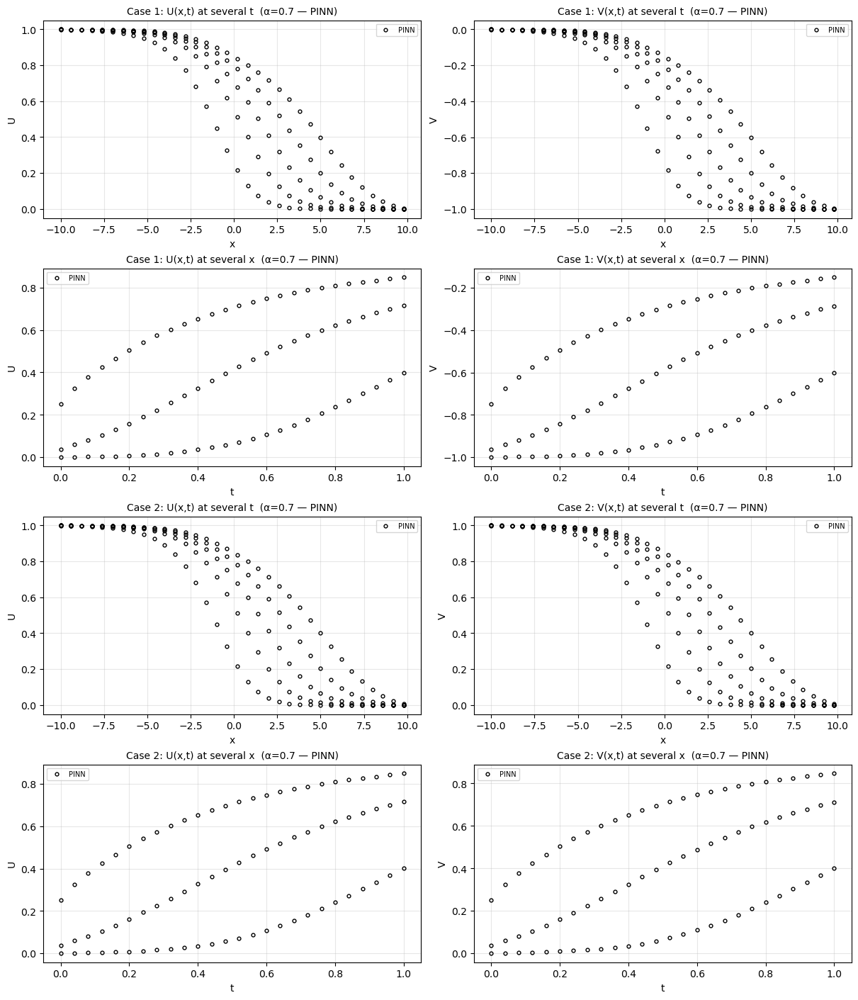

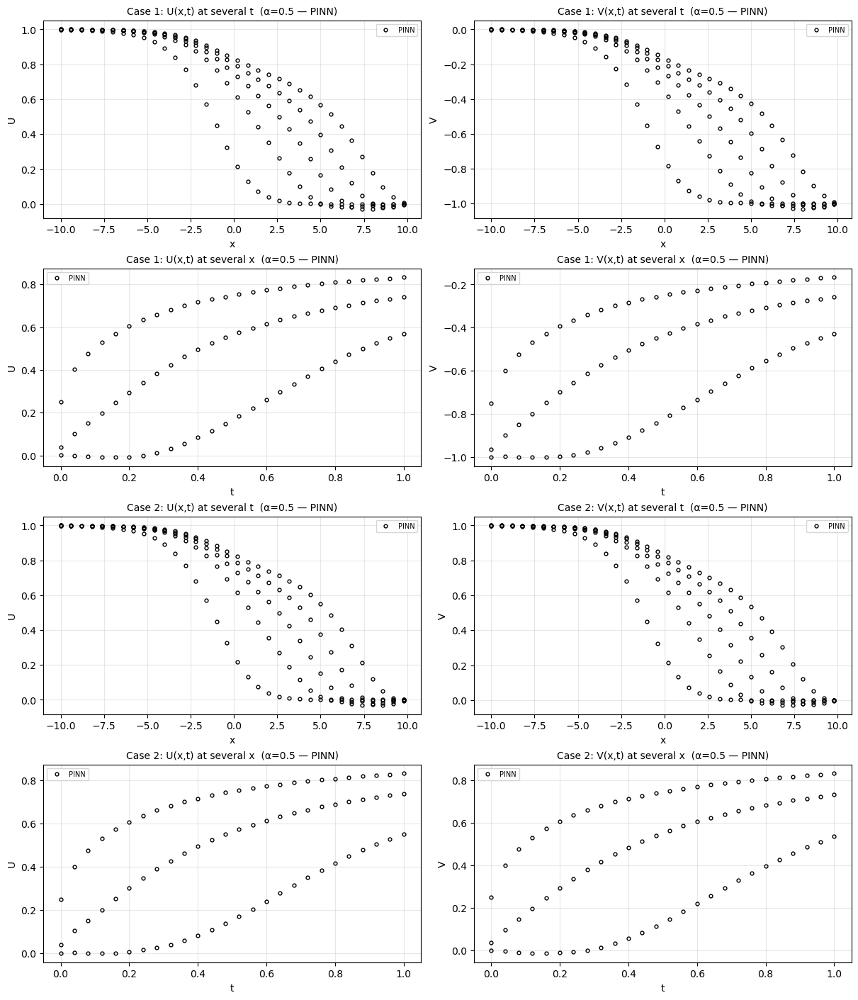

In [17]:
# ============================================================================
# الخلية 8-ج: مقاطع PINN + الدقيق (عند α=1 فقط)
# - لكل α: شكل 4×2 (صفان لكل حالة × عمودان للمتغير)
#   الصف 2i   : مقاطع في x عند أزمنة مختلفة
#   الصف 2i+1 : مقاطع في t عند مواضع x مختلفة
# - عند α=1: Exact (خطوط ملونة) + PINN (دوائر سوداء)
# - عند α<1: PINN فقط (لا مرجع)
# - ✅ لا تكرار: كل (α, حالة, متغير, نوع) في لوحة واحدة
# ============================================================================
t_list  = [0.0, 0.25, 0.5, 0.75, 1.0]
x_probe = [0.0, 2.0, 5.0]
colors_t = plt.cm.tab10(np.linspace(0, 1, len(t_list)))   # ✅ 5 ألوان لـ 5 أزمنة
colors_x = plt.cm.tab10(np.linspace(0, 1, len(x_probe)))  # ✅ 3 ألوان لـ 3 مواضع

for a in ALPHAS:
    is_alpha_one = abs(a - 1.0) < 1e-12                    # ✅ مقارنة آمنة
    fig, axs = plt.subplots(4, 2, figsize=(12, 14),
                            constrained_layout=True)       # ✅ بدل tight_layout

    for i, c in enumerate(CASES):
        if (c, a) not in pinn:
            print(f"⚠️ لا يوجد PINN لـ (case={c}, α={a}) — تخطٍ")
            continue
        P = pinn[(c, a)]

        for j, name in enumerate(("U", "V")):
            # ---- (1) مقاطع x عند أزمنة مختلفة ----
            ax = axs[2*i, j]
            for tv, col in zip(t_list, colors_t):
                it = int(np.argmin(np.abs(ts - tv)))
                if is_alpha_one:
                    ax.plot(xs, EX[c][j][:, it], "-", color=col, lw=2,
                            label=f"Exact t={ts[it]:.2f}")
                ax.plot(xs[::6], P[j][::6, it], "o", color="k",
                        ms=3.5, mfc="none",
                        label="PINN" if tv == t_list[0] else None)
            title = f"Case {c}: {name}(x,t) at several t  (α={a}"
            title += " — PINN vs Exact)" if is_alpha_one else " — PINN)"
            ax.set_title(title, fontsize=10)
            ax.set_xlabel("x"); ax.set_ylabel(name)
            ax.grid(alpha=.3); ax.legend(fontsize=7, loc="best")

            # ---- (2) مقاطع t عند مواضع x مختلفة ----
            ax = axs[2*i+1, j]
            for xv, col in zip(x_probe, colors_x):
                ix = int(np.argmin(np.abs(xs - xv)))
                if is_alpha_one:
                    ax.plot(ts, EX[c][j][ix], "-", color=col, lw=2,
                            label=f"Exact x={xs[ix]:.1f}")
                ax.plot(ts[::4], P[j][ix, ::4], "o", color="k",
                        ms=3.5, mfc="none",
                        label="PINN" if xv == x_probe[0] else None)
            title = f"Case {c}: {name}(x,t) at several x  (α={a}"
            title += " — PINN vs Exact)" if is_alpha_one else " — PINN)"
            ax.set_title(title, fontsize=10)
            ax.set_xlabel("t"); ax.set_ylabel(name)
            ax.grid(alpha=.3); ax.legend(fontsize=7, loc="best")

    fname = f"figures/pinn_vs_exact_slices_alpha{int(a*10):02d}.png"
    plt.savefig(fname, dpi=170, bbox_inches="tight")
    plt.show(); plt.close(fig)                             # ✅ تحرير الذاكرة

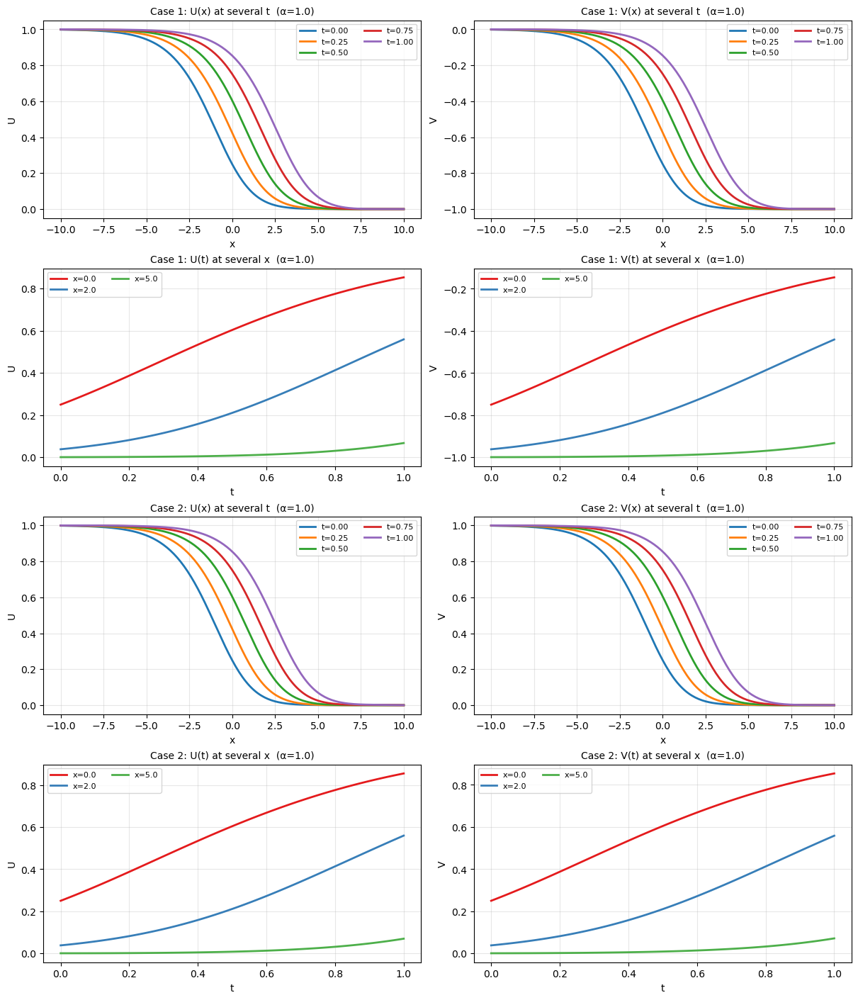

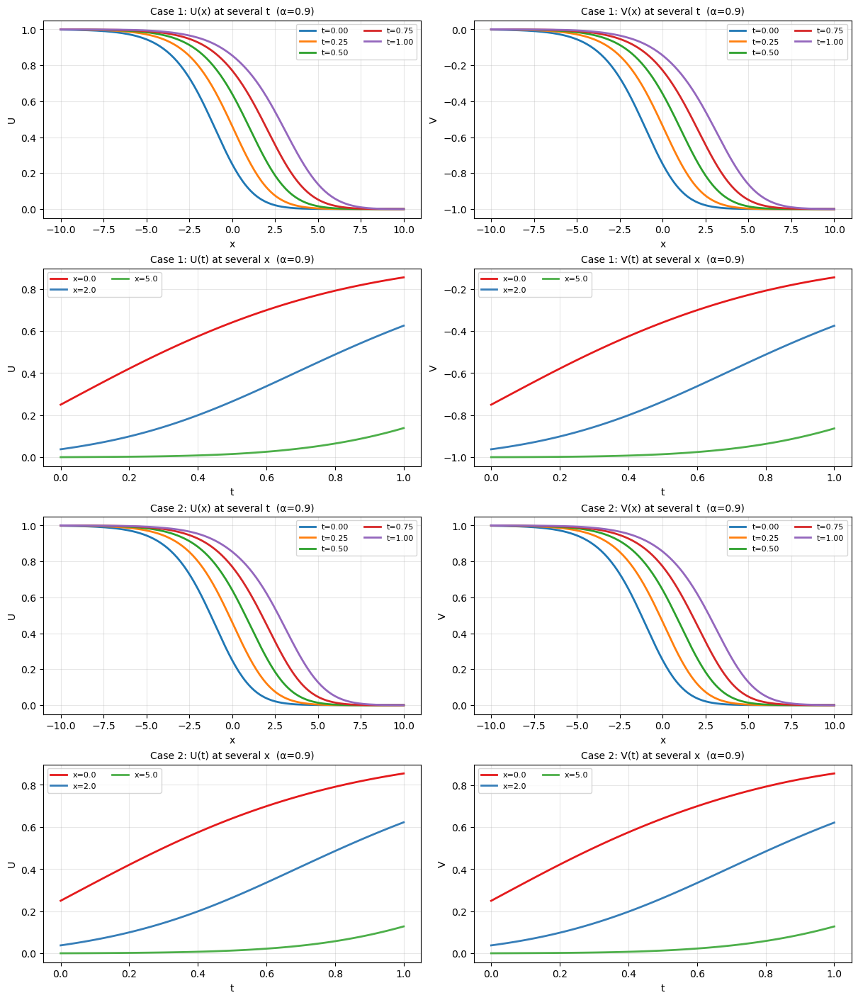

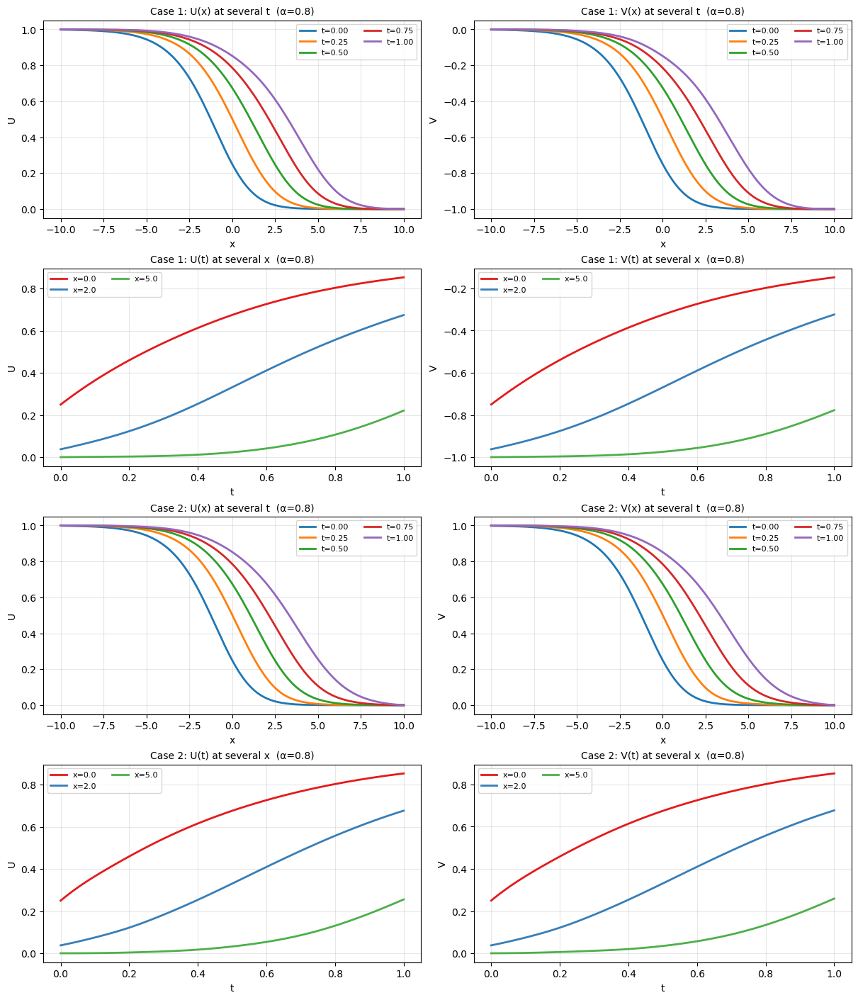

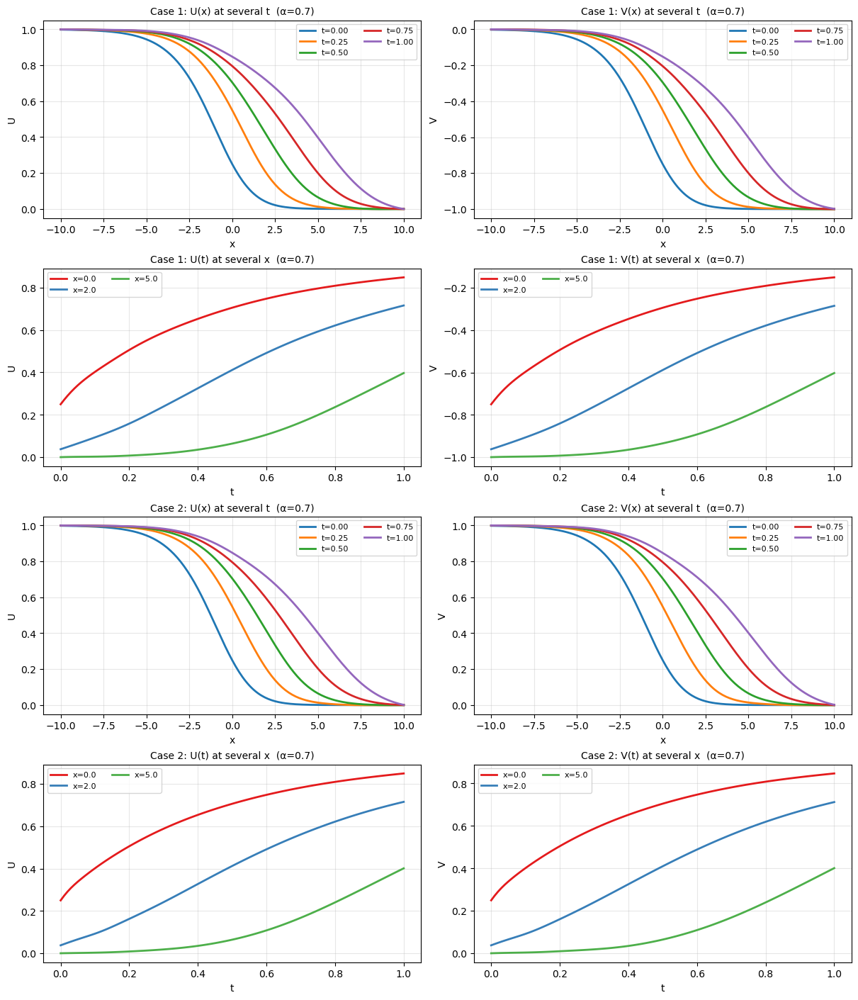

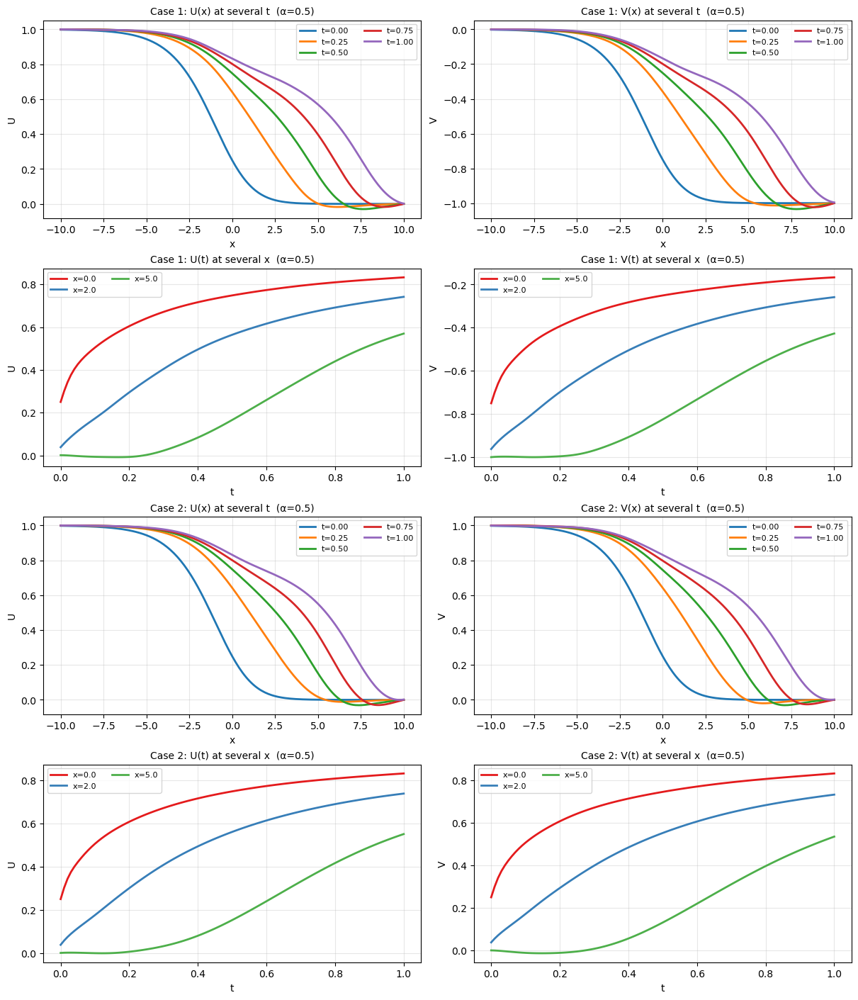

In [21]:
# ============================================================================
# الخلية 8-ج (نسخة PINN فقط): مقاطع PINN عند كل α
# ============================================================================
# - لكل α: شكل 4×2 (صفان لكل حالة × عمودان للمتغير)
#     الصف 2i   : مقاطع في x عند أزمنة مختلفة (t_list)
#     الصف 2i+1 : مقاطع في t عند مواضع x مختلفة (x_probe)
# - PINN فقط: خطوط متصلة بألوان مختلفة لكل قيمة t / x
# - ✅ يعمل لكل α (1.0، 0.9، 0.8، 0.7، 0.5) دون أي اعتماد على EX
# - ✅ حماية من KeyError، تحرير الذاكرة
# ============================================================================

import matplotlib.pyplot as plt
import numpy as np

# ---- إعدادات المقاطع ----
t_list  = [0.0, 0.25, 0.5, 0.75, 1.0]          # أزمنة للمقاطع في x
x_probe = [0.0, 2.0, 5.0]                       # مواضع للمقاطع في t

# ألوان مخصصة لكل خط (واضحة ومتمايزة)
colors_t = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]  # 5 ألوان لـ 5 أزمنة
colors_x = ["#e41a1c", "#377eb8", "#4daf4a"]                          # 3 ألوان لـ 3 مواضع

# ---- حلقة على كل قيم α ----
for a in ALPHAS:
    fig, axs = plt.subplots(4, 2, figsize=(12, 14),
                            constrained_layout=True)

    for i, c in enumerate(CASES):
        # حماية من KeyError
        if (c, a) not in pinn:
            print(f"⚠️ لا يوجد PINN لـ (case={c}, α={a}) — تخطٍ")
            continue

        P = pinn[(c, a)]                         # (U_2d, V_2d)

        for j, name in enumerate(("U", "V")):

            # ============================================================
            # (1) مقاطع في x عند أزمنة مختلفة — لون مختلف لكل t
            # ============================================================
            ax = axs[2*i, j]
            for tv, col in zip(t_list, colors_t):
                it = int(np.argmin(np.abs(ts - tv)))
                ax.plot(xs, P[j][:, it], "-", color=col, lw=2,
                        label=f"t={ts[it]:.2f}")
            ax.set_title(f"Case {c}: {name}(x) at several t  (α={a})",
                         fontsize=10)
            ax.set_xlabel("x"); ax.set_ylabel(name)
            ax.grid(alpha=.3)
            ax.legend(fontsize=8, loc="best", ncol=2)

            # ============================================================
            # (2) مقاطع في t عند مواضع x مختلفة — لون مختلف لكل x
            # ============================================================
            ax = axs[2*i + 1, j]
            for xv, col in zip(x_probe, colors_x):
                ix = int(np.argmin(np.abs(xs - xv)))
                ax.plot(ts, P[j][ix], "-", color=col, lw=2,
                        label=f"x={xs[ix]:.1f}")
            ax.set_title(f"Case {c}: {name}(t) at several x  (α={a})",
                         fontsize=10)
            ax.set_xlabel("t"); ax.set_ylabel(name)
            ax.grid(alpha=.3)
            ax.legend(fontsize=8, loc="best", ncol=2)

    # ---- حفظ وإغلاق ----
    fname = f"figures/pinn_slices_only_alpha{int(round(a*10)):02d}.png"
    plt.savefig(fname, dpi=170, bbox_inches="tight")
    plt.show()
    plt.close(fig)

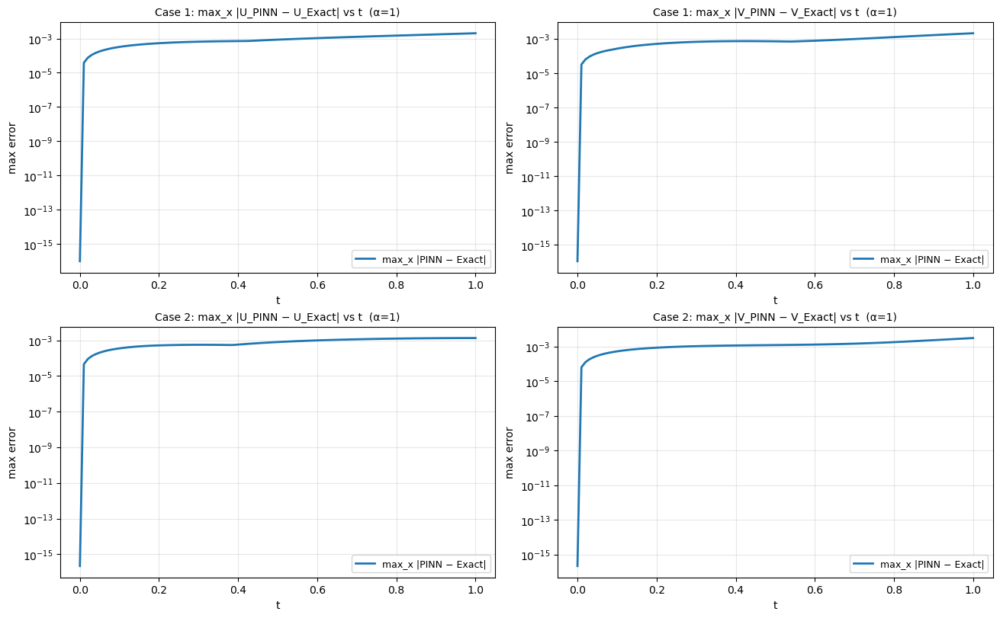

In [22]:
# ============================================================================
# الخلية 8-د: الخطأ عند α=1 — max_x |PINN − Exact| مقابل t
# - شكل 2×2 (حالة × متغير)
# - مقياس لوغاريتمي
# - عند α=1 فقط (لا مرجع دقيق عند α<1)
# - ✅ حماية من KeyError، NaN، تحرير الذاكرة
# ============================================================================
has_alpha_one = any(abs(a - 1.0) < 1e-12 for a in ALPHAS)

if has_alpha_one:
    fig, axs = plt.subplots(2, 2, figsize=(13, 8),
                            constrained_layout=True)      # ✅ بدل tight_layout
    for i, c in enumerate(CASES):
        if (c, 1.0) not in pinn:
            print(f"⚠️ لا يوجد PINN لـ (case={c}, α=1.0) — تخطٍ")
            for j in range(2):
                axs[i, j].axis("off")
            continue
        for j, name in enumerate(("U", "V")):
            ax = axs[i, j]
            err = np.abs(pinn[(c, 1.0)][j] - EX[c][j])
            err = np.where(np.isfinite(err), err, np.nan)  # ✅ حماية NaN
            err_max = np.nanmax(err, axis=0)               # ✅ تجاهل NaN
            ax.semilogy(ts, np.maximum(err_max, 1e-16), lw=2,
                        label="max_x |PINN − Exact|")
            ax.set_title(f"Case {c}: max_x |{name}_PINN − {name}_Exact| vs t  (α=1)",
                         fontsize=10)
            ax.set_xlabel("t"); ax.set_ylabel("max error")
            ax.grid(alpha=.3, which="both")
            ax.legend(fontsize=9)
    plt.savefig("figures/error_pinn_vs_exact_alpha1.png",
                dpi=170, bbox_inches="tight")
    plt.show(); plt.close(fig)                             # ✅ تحرير الذاكرة
else:
    print("⚠️ لا يمكن إجراء المقارنة: الحل الدقيق غير متاح (α=1 غير موجود في ALPHAS).")

## 9) مقارنة قيم α للطريقتين (على نمط الشكلين 7 و8 في الورقة)

لكل نوع رسم: العمود الأيسر α=1 (الحل الدقيق + العددي + PINN)، والعمود الأيمن قيم α<1 (العددي خط مستمر، PINN دوائر مفرغة بنفس اللون).

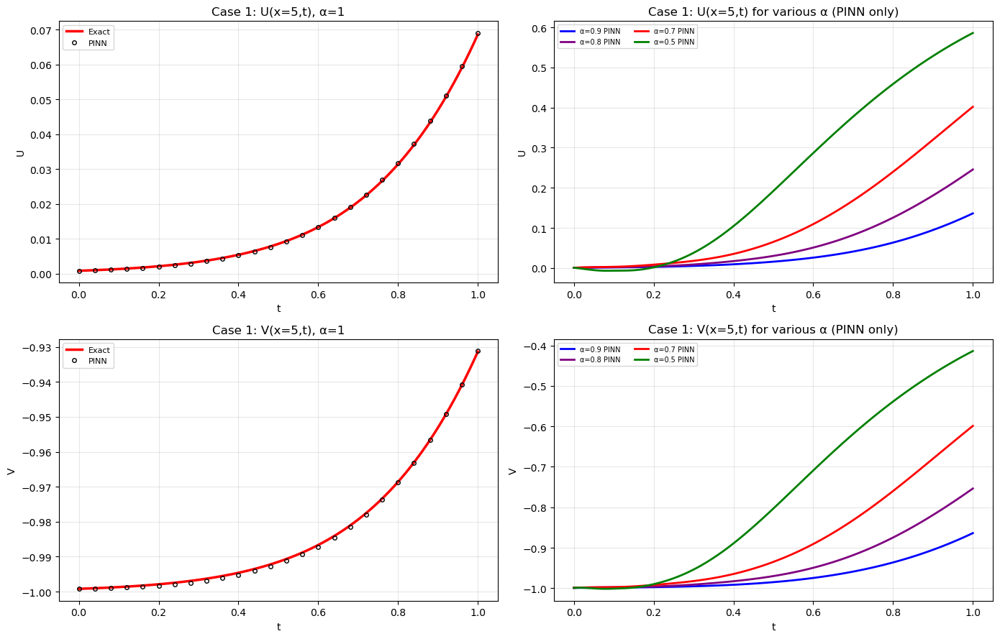

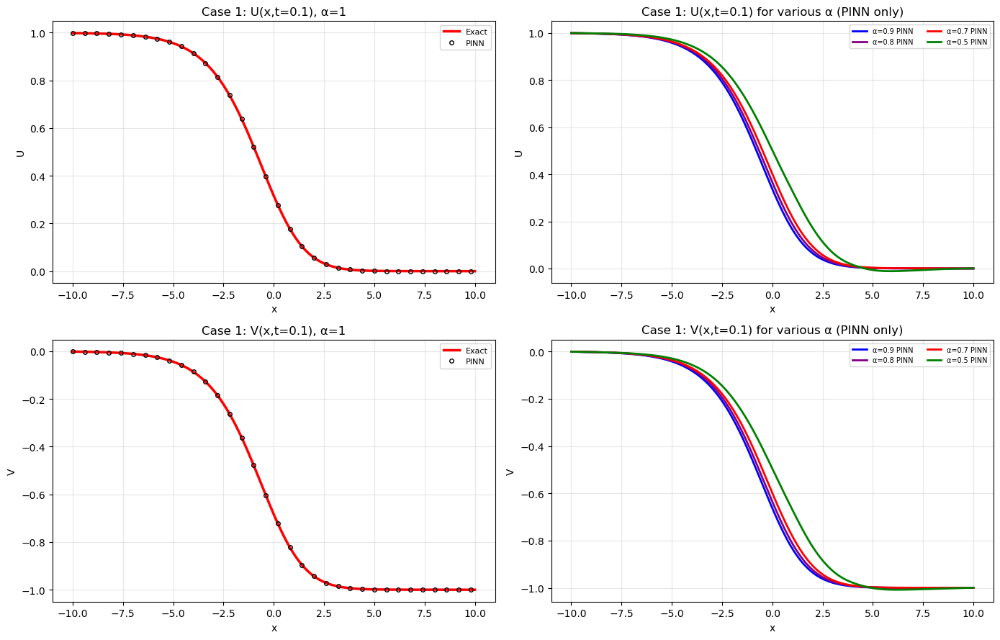

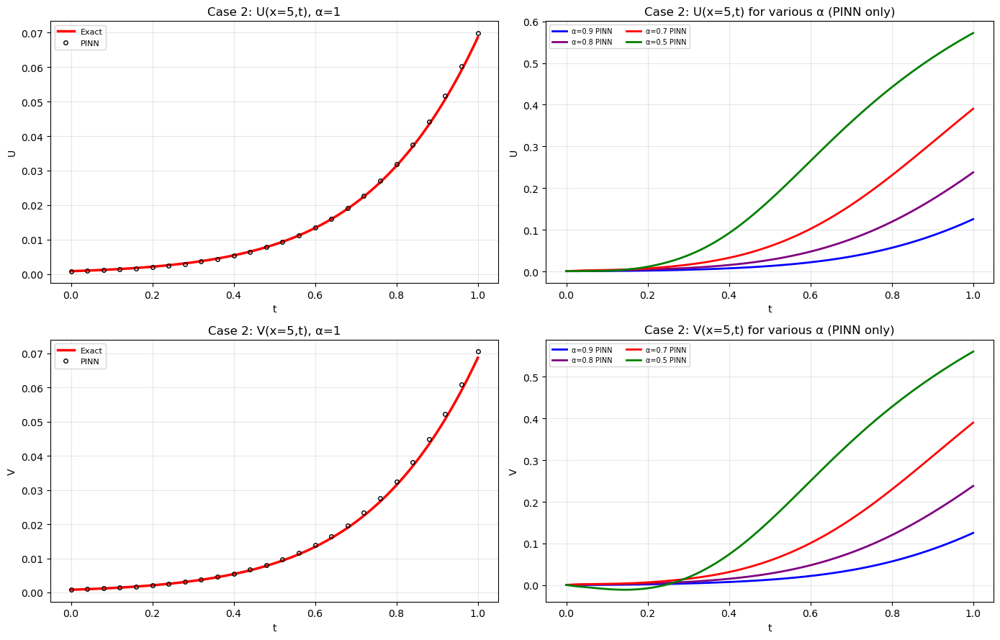

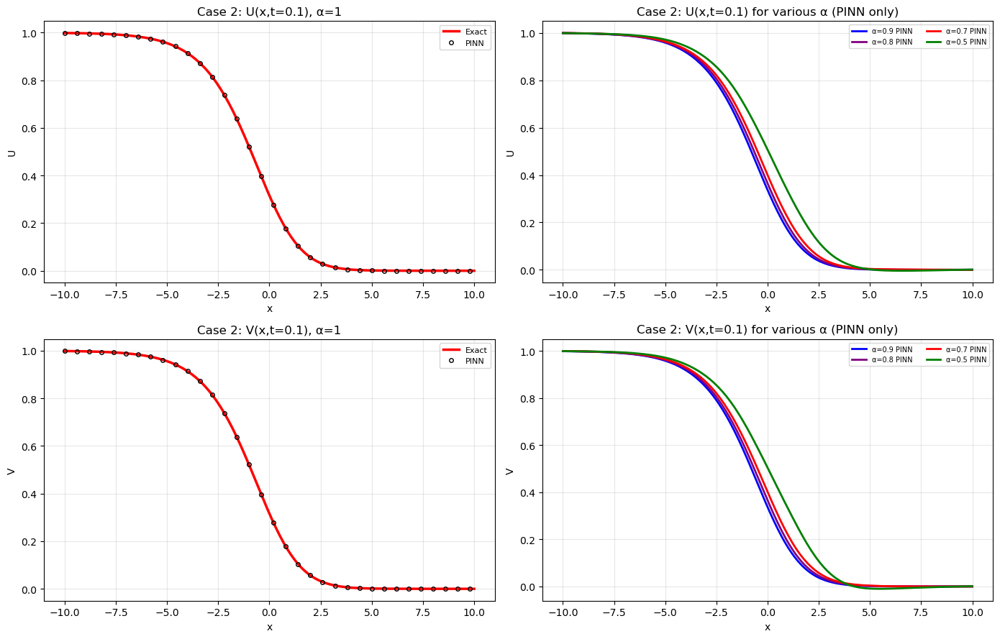

,case,alpha,U_pinn,V_pinn,U_exact,V_exact
0,1,1.000e+00,6.908e-02,-9.312e-01,6.865e-02,-9.313e-01
1,1,9.000e-01,1.363e-01,-8.639e-01,NaN,NaN
2,1,8.000e-01,2.457e-01,-7.536e-01,NaN,NaN
3,1,7.000e-01,4.020e-01,-5.987e-01,NaN,NaN
4,1,5.000e-01,5.860e-01,-4.137e-01,NaN,NaN
5,2,1.000e+00,6.992e-02,7.046e-02,6.865e-02,6.865e-02
6,2,9.000e-01,1.255e-01,1.255e-01,NaN,NaN
7,2,8.000e-01,2.378e-01,2.381e-01,NaN,NaN
8,2,7.000e-01,3.903e-01,3.900e-01,NaN,NaN
9,2,5.000e-01,5.720e-01,5.602e-01,NaN,NaN


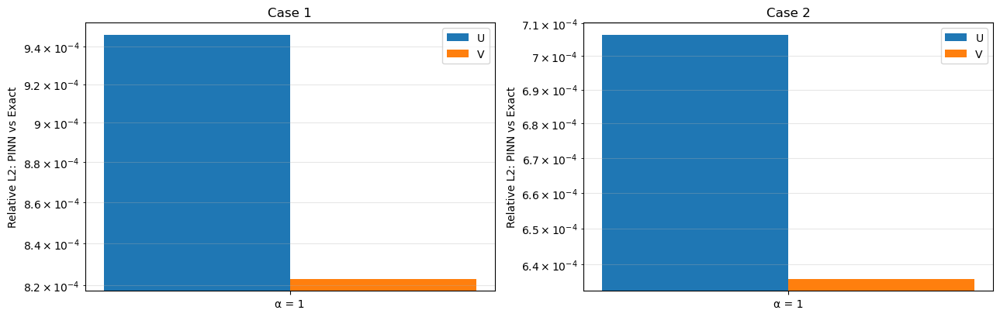

In [63]:
# ============================ 9) رسوم على نمط الشكلين 7 و 8 ============================
# تم حذف FD-L1 — المرجع الوحيد الآن هو الحل الدقيق (متاح فقط عند α = 1)
# التعديلات: α=0.3 → α=0.8، و t=0.01 → t=0.1

ALPHAS_FRAC = [0.9, 0.8, 0.7, 0.5]                          # ← صريحة، لا تعتمد على ALPHAS
acol = {0.9: "blue", 0.8: "purple", 0.7: "red", 0.5: "green"}
_cyc = plt.rcParams["axes.prop_cycle"].by_key()["color"]
def col_of(a): return acol.get(a, _cyc[ALPHAS_FRAC.index(a) % len(_cyc)])

ix = np.argmin(np.abs(xs - 5.0))
it = np.argmin(np.abs(ts - 0.1))                             # ← t = 0.1 بدلاً من 0.01


def alpha_figure(c, kind):
    """kind='time': U(x=5,t),V(x=5,t) (الشكل 7)   |   kind='space': U(x,t=0.1),V(x,t=0.1) (الشكل 8)"""
    axis = ts if kind == "time" else xs
    sel = (lambda Z: Z[ix, :]) if kind == "time" else (lambda Z: Z[:, it])
    step = 4 if kind == "time" else 6
    fig, axs = plt.subplots(2, 2, figsize=(14, 9))
    for j, name in enumerate(("U", "V")):
        ttl = f"{name}(x=5,t)" if kind == "time" else f"{name}(x,t=0.1)"

        # ---- (1) العمود الأيسر: α = 1 (Exact vs PINN) ----
        ax = axs[j, 0]
        if 1.0 in ALPHAS:
            ax.plot(axis, sel(EX[c][j]), "r-", lw=2.5, label="Exact")
            ax.plot(axis[::step], sel(pinn[(c, 1.0)][j])[::step], "ko", ms=4,
                    mfc="none", label="PINN")
        ax.set_title(f"Case {c}: {ttl}, α=1")
        ax.set_xlabel("t" if kind == "time" else "x")
        ax.set_ylabel(name); ax.grid(alpha=.3); ax.legend(fontsize=8)

        # ---- (2) العمود الأيمن: α < 1 (PINN فقط) ----
        ax = axs[j, 1]
        for a in ALPHAS_FRAC:
            ax.plot(axis, sel(pinn[(c, a)][j]), "-", color=col_of(a), lw=2,
                    label=f"α={a} PINN")
        ax.set_title(f"Case {c}: {ttl} for various α (PINN only)")
        ax.set_xlabel("t" if kind == "time" else "x")
        ax.set_ylabel(name); ax.grid(alpha=.3)
        ax.legend(fontsize=7, ncol=2)

    plt.tight_layout()
    fn = (f"figures/fig7_style_x5_case{c}.png" if kind == "time"
          else f"figures/fig8_style_t01_case{c}.png")
    plt.savefig(fn, dpi=180); plt.show()


for c in CASES:
    alpha_figure(c, "time")      # على نمط الشكل 7
    alpha_figure(c, "space")     # على نمط الشكل 8


# ---- جدول قيم U(5, 0.5) و V(5, 0.5): Exact (عند α=1) / PINN لكل α ----
rows = []
for c in CASES:
    for a in [1.0] + ALPHAS_FRAC:                            # ← يشمل α=1 و 0.9, 0.8, 0.7, 0.5
        r = dict(case=c, alpha=a,
                 U_pinn=pinn[(c, a)][0][ix, -1],
                 V_pinn=pinn[(c, a)][1][ix, -1])
        if a == 1.0:
            r.update(U_exact=EX[c][0][ix, -1], V_exact=EX[c][1][ix, -1])
        rows.append(r)
df_x5 = pd.DataFrame(rows)
display(df_x5)
df_x5.to_csv("figures/values_x5_t05.csv", index=False)


# ---- خطأ PINN مقابل Exact عند α = 1 (U و V) ----
if 1.0 in ALPHAS:
    fig, axs = plt.subplots(1, len(CASES), figsize=(6.5*len(CASES), 4.2), squeeze=False)
    for i, c in enumerate(CASES):
        ax = axs[0, i]
        vals_U = [np.linalg.norm(pinn[(c, 1.0)][0] - EX[c][0]) / np.linalg.norm(EX[c][0])]
        vals_V = [np.linalg.norm(pinn[(c, 1.0)][1] - EX[c][1]) / np.linalg.norm(EX[c][1])]
        w = 0.35
        ax.bar([0 - w/2], vals_U, w, label="U")
        ax.bar([0 + w/2], vals_V, w, label="V")
        ax.set_yscale("log")
        ax.set_xticks([0]); ax.set_xticklabels(["α = 1"])
        ax.set_ylabel("Relative L2: PINN vs Exact")
        ax.set_title(f"Case {c}")
        ax.grid(alpha=.3, which="both", axis="y"); ax.legend()
    plt.tight_layout()
    plt.savefig("figures/pinn_vs_exact_error_alpha1.png", dpi=180)
    plt.show()
else:
    print("⚠️ لا يمكن حساب الخطأ النسبي: الحل الدقيق غير متاح (α=1 غير موجود في ALPHAS).")

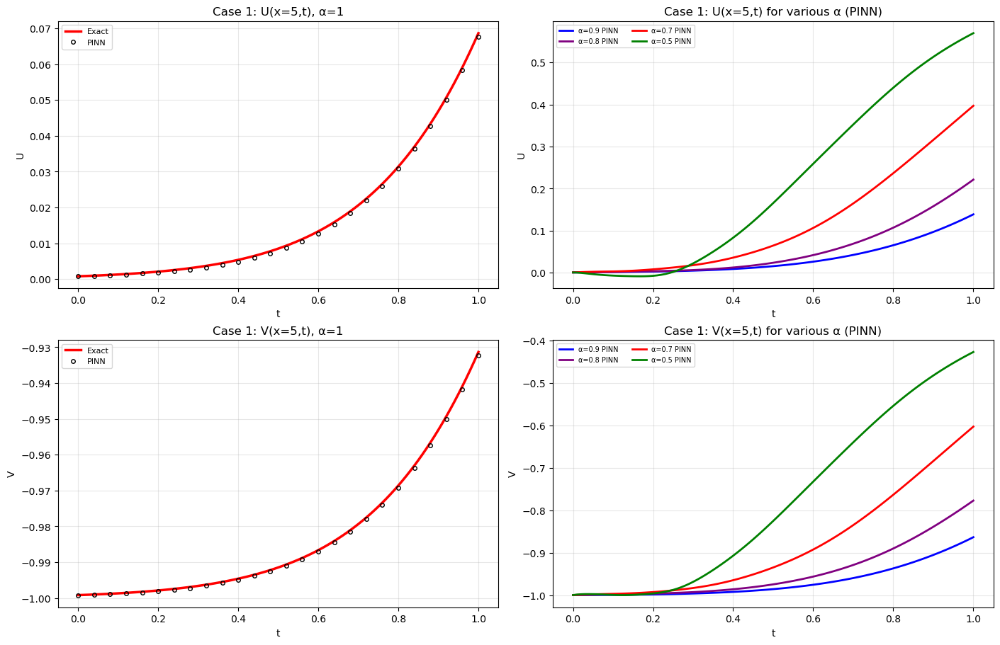

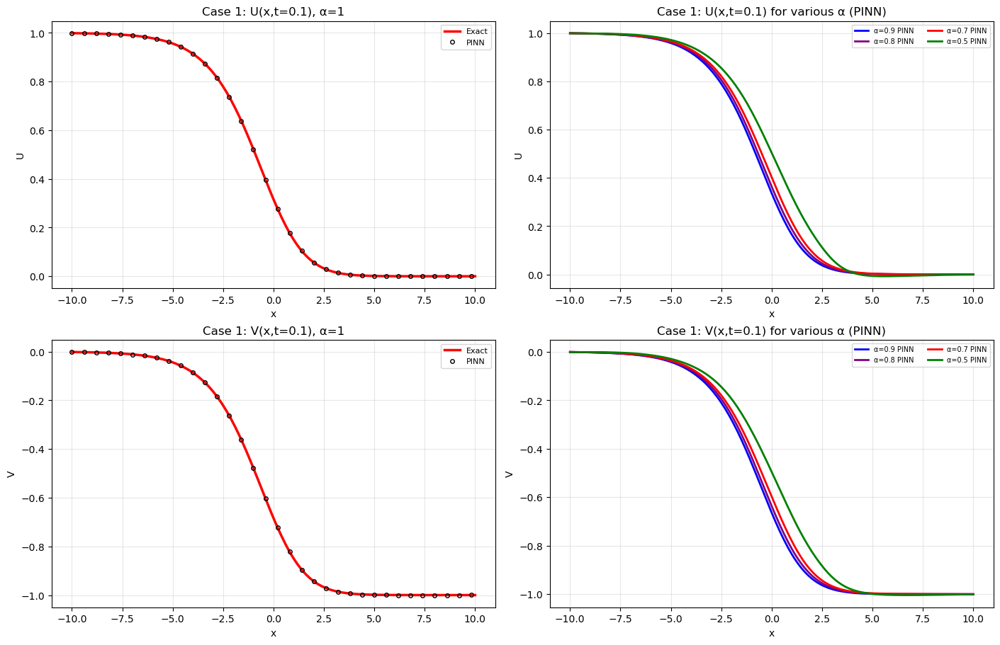

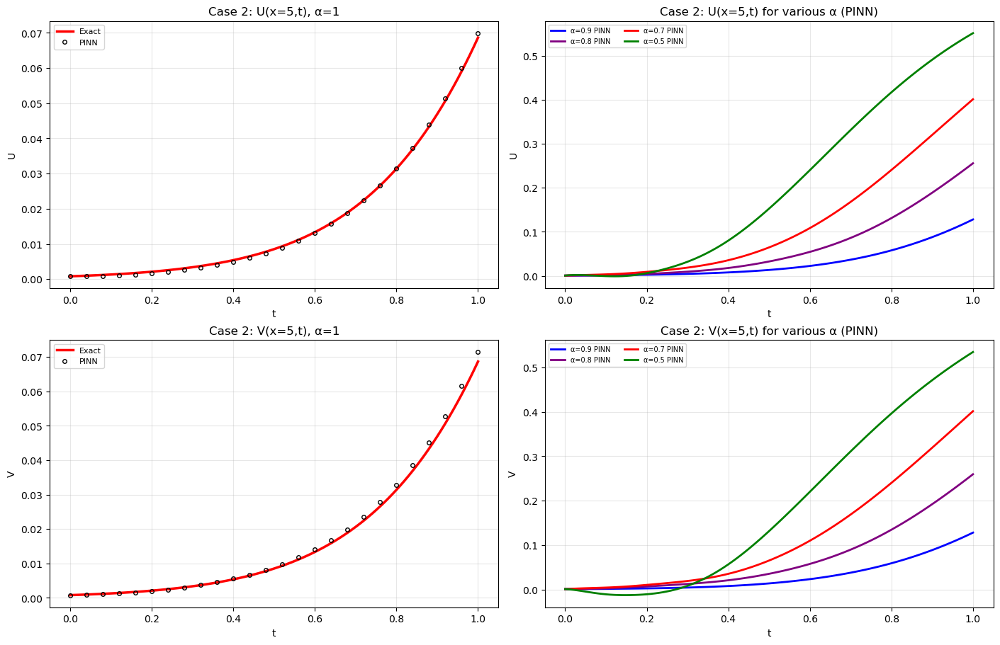

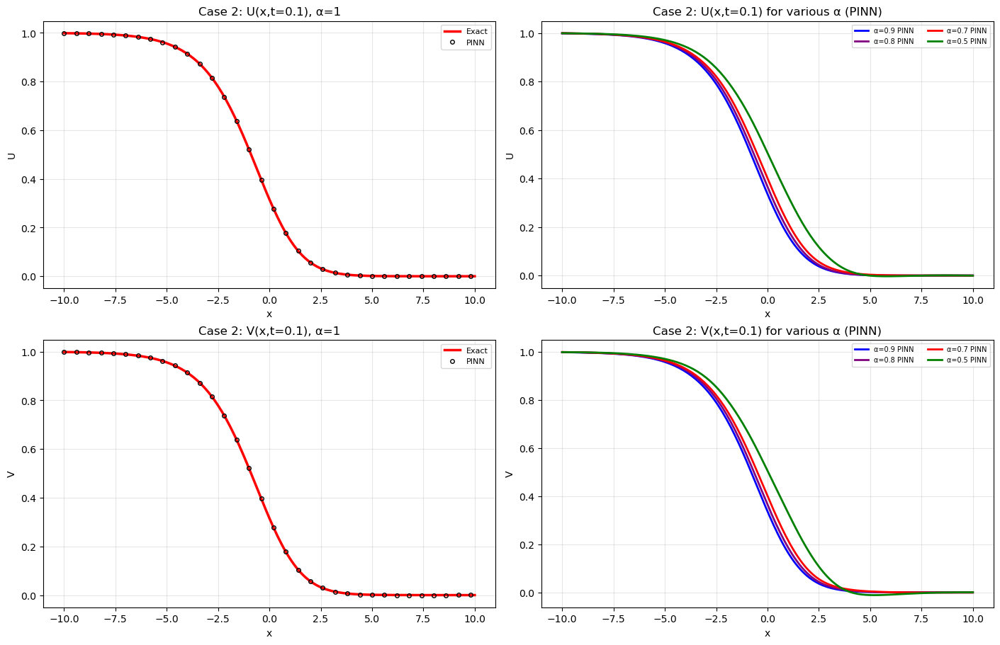

,case,alpha,U_pinn,V_pinn,U_exact,V_exact
0,1,1.0,0.007963,-0.991784,0.008524,-0.991476
1,1,0.9,0.015751,-0.985234,NaN,NaN
2,1,0.8,0.023853,-0.973971,NaN,NaN
3,1,0.7,0.064668,-0.934248,NaN,NaN
4,1,0.5,0.165720,-0.824759,NaN,NaN
5,2,1.0,0.008133,0.008930,0.008524,0.008524
6,2,0.9,0.013574,0.013699,NaN,NaN
7,2,0.8,0.032793,0.035306,NaN,NaN
8,2,0.7,0.064745,0.065182,NaN,NaN
9,2,0.5,0.152794,0.131473,NaN,NaN


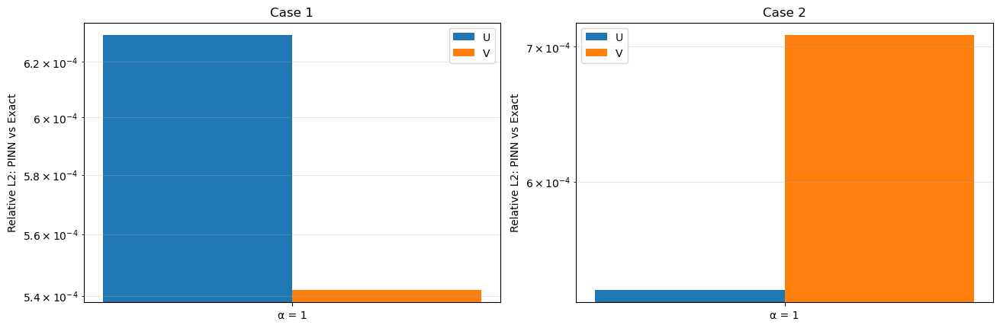

In [24]:
# ============================================================================
# الخلية 9: رسوم على نمط الشكلين 7 و8
# - alpha_figure(c, "time")  : U(x=5,t) و V(x=5,t) لكل α (نمط الشكل 7)
# - alpha_figure(c, "space") : U(x,t=0.1) و V(x,t=0.1) لكل α (نمط الشكل 8)
# - جدول df_x5: U(5, 0.5) و V(5, 0.5) لكل α
# - مخطط أعمدة: Relative L2 عند α=1
# - ✅ ALPHAS_FRAC = [0.9, 0.8, 0.7, 0.5] (حذف 0.3 وإضافة 0.8)
# ============================================================================

ALPHAS_FRAC = [0.9, 0.8, 0.7, 0.5]
acol = {0.9: "blue", 0.8: "purple", 0.7: "red", 0.5: "green"}
def col_of(a): return acol[a]

ix = int(np.argmin(np.abs(xs - 5.0)))           # x=5.0 → index 150
it = int(np.argmin(np.abs(ts - 0.1)))           # t=0.1 → index 10
it_05 = int(np.argmin(np.abs(ts - 0.5)))        # t=0.5 → index 50
has_alpha_one = any(abs(a - 1.0) < 1e-12 for a in ALPHAS)


def alpha_figure(c, kind):
    """kind='time': U(x=5,t),V(x=5,t) | kind='space': U(x,t=0.1),V(x,t=0.1)"""
    axis = ts if kind == "time" else xs
    sel = (lambda Z: Z[ix, :]) if kind == "time" else (lambda Z: Z[:, it])
    step = 4 if kind == "time" else 6

    fig, axs = plt.subplots(2, 2, figsize=(14, 9),
                            constrained_layout=True)
    for j, name in enumerate(("U", "V")):
        ttl = f"{name}(x=5,t)" if kind == "time" else f"{name}(x,t=0.1)"

        # ---- (1) α=1: Exact vs PINN ----
        ax = axs[j, 0]
        if has_alpha_one and (c, 1.0) in pinn:
            ax.plot(axis, sel(EX[c][j]), "r-", lw=2.5, label="Exact")
            ax.plot(axis[::step], sel(pinn[(c, 1.0)][j])[::step],
                    "ko", ms=4, mfc="none", label="PINN")
        ax.set_title(f"Case {c}: {ttl}, α=1")
        ax.set_xlabel("t" if kind == "time" else "x")
        ax.set_ylabel(name); ax.grid(alpha=.3)
        ax.legend(fontsize=8)

        # ---- (2) α<1: PINN فقط ----
        ax = axs[j, 1]
        for a in ALPHAS_FRAC:
            if (c, a) not in pinn: continue
            ax.plot(axis, sel(pinn[(c, a)][j]), "-",
                    color=col_of(a), lw=2, label=f"α={a} PINN")
        ax.set_title(f"Case {c}: {ttl} for various α (PINN)")
        ax.set_xlabel("t" if kind == "time" else "x")
        ax.set_ylabel(name); ax.grid(alpha=.3)
        ax.legend(fontsize=7, ncol=2)

    fn = (f"figures/fig7_style_x5_case{c}.png" if kind == "time"
          else f"figures/fig8_style_t01_case{c}.png")
    plt.savefig(fn, dpi=180, bbox_inches="tight")
    plt.show(); plt.close(fig)


for c in CASES:
    alpha_figure(c, "time")
    alpha_figure(c, "space")


# ---- جدول U(5, 0.5) و V(5, 0.5) لكل α ----
rows = []
for c in CASES:
    for a in [1.0] + ALPHAS_FRAC:
        if (c, a) not in pinn: continue
        r = dict(case=c, alpha=a,
                 U_pinn=pinn[(c, a)][0][ix, it_05],   # ✅ t=0.5 (كان -1)
                 V_pinn=pinn[(c, a)][1][ix, it_05])
        if abs(a - 1.0) < 1e-12:
            r.update(U_exact=EX[c][0][ix, it_05],
                     V_exact=EX[c][1][ix, it_05])
        rows.append(r)
df_x5 = pd.DataFrame(rows)
display(df_x5)
df_x5.to_csv("figures/values_x5_t05.csv", index=False, encoding="utf-8-sig")


# ---- خطأ PINN مقابل Exact عند α=1 ----
if has_alpha_one:
    fig, axs = plt.subplots(1, len(CASES),
                            figsize=(6.5*len(CASES), 4.2),
                            squeeze=False, constrained_layout=True)
    for i, c in enumerate(CASES):
        ax = axs[0, i]
        if (c, 1.0) not in pinn:
            ax.text(0.5, 0.5, "no PINN", transform=ax.transAxes, ha="center")
            continue
        val_U = (np.linalg.norm(pinn[(c, 1.0)][0] - EX[c][0])
                 / np.linalg.norm(EX[c][0]))
        val_V = (np.linalg.norm(pinn[(c, 1.0)][1] - EX[c][1])
                 / np.linalg.norm(EX[c][1]))
        w = 0.35
        ax.bar([-w/2], [val_U], w, label="U")
        ax.bar([+w/2], [val_V], w, label="V")
        ax.set_yscale("log")
        ax.set_xticks([0]); ax.set_xticklabels(["α = 1"])
        ax.set_ylabel("Relative L2: PINN vs Exact")
        ax.set_title(f"Case {c}")
        ax.grid(alpha=.3, which="both", axis="y"); ax.legend()
    plt.savefig("figures/pinn_vs_exact_error_alpha1.png",
                dpi=180, bbox_inches="tight")
    plt.show(); plt.close(fig)
else:
    print("⚠️ α=1 غير موجود في ALPHAS — لا مخطط خطأ.")

## ملاحظات
- **الحالة 1 والحالة 2** تشتركان في نفس الموجة $U$ (معادلة Fisher–KPP: $U_t=U_{xx}+\xi U(1-U)$)، والفرق في $V$: في الحالة 1 $V=\frac{1-\xi}{\rho}(1-U)$ وفي الحالة 2 $V=\frac{\xi-1}{\rho}U$. هذا ما يفسر تشابه سطحي $U$ واختلاف سطحي $V$.
- القيمة الصغيرة جداً لباقي المعادلة عند التحقق الذاتي تؤكد أن الصيغ المأخوذة من الصور صحيحة للحالتين لأي قيمتين $\xi,\rho$.
- لتجربة سريعة اجعل `FAST_MODE = True`. للحالة الكسرية أضف قيماً إلى `ALPHAS` (التدريب يصبح أبطأ لأن مخطط L1 يحتاج الشبكة الزمنية الكاملة).

In [25]:
# ============================================================================
# جدول U(5, t) و V(5, t) لكل t ∈ [0, 1]، لكل α
# ============================================================================
rows = []
for c in CASES:
    for a in [1.0] + ALPHAS_FRAC:
        if (c, a) not in pinn:
            continue
        for it, tv in enumerate(ts):
            r = dict(case=c, alpha=round(a, 2), t=round(float(tv), 4),
                     U_pinn=float(pinn[(c, a)][0][ix, it]),
                     V_pinn=float(pinn[(c, a)][1][ix, it]))
            if abs(a - 1.0) < 1e-12:
                r.update(U_exact=float(EX[c][0][ix, it]),
                         V_exact=float(EX[c][1][ix, it]))
            rows.append(r)

df_x5_all_t = pd.DataFrame(rows)
print(f"عدد الصفوف: {len(df_x5_all_t)}  (متوقع: {len(CASES)*(1+len(ALPHAS_FRAC))*(NT+1)})")
display(df_x5_all_t.head(10))
df_x5_all_t.to_csv("figures/values_x5_all_t.csv",
                   index=False, encoding="utf-8-sig")

# ---- ملخص: القيم عند t=0, t=0.5, t=1.0 فقط ----
summary = df_x5_all_t[df_x5_all_t["t"].isin([0.0, 0.5, 1.0])]
display(summary)
summary.to_csv("figures/values_x5_summary.csv",
               index=False, encoding="utf-8-sig")

عدد الصفوف: 1010  (متوقع: 1010)


,case,alpha,t,U_pinn,V_pinn,U_exact,V_exact
0,1,1.0,0.00,0.000802,-0.999198,0.000802,-0.999198
1,1,1.0,0.01,0.000832,-0.999184,0.000842,-0.999158
2,1,1.0,0.02,0.000863,-0.999167,0.000884,-0.999116
3,1,1.0,0.03,0.000897,-0.999146,0.000928,-0.999072
4,1,1.0,0.04,0.000931,-0.999121,0.000974,-0.999026
5,1,1.0,0.05,0.000968,-0.999093,0.001022,-0.998978
6,1,1.0,0.06,0.001007,-0.999061,0.001073,-0.998927
7,1,1.0,0.07,0.001048,-0.999026,0.001126,-0.998874
8,1,1.0,0.08,0.001091,-0.998986,0.001181,-0.998819
9,1,1.0,0.09,0.001137,-0.998943,0.001240,-0.998760


,case,alpha,t,U_pinn,V_pinn,U_exact,V_exact
0,1,1.0,0.0,0.000802,-0.999198,0.000802,-0.999198
50,1,1.0,0.5,0.007963,-0.991784,0.008524,-0.991476
100,1,1.0,1.0,0.067693,-0.932284,0.068651,-0.931349
101,1,0.9,0.0,0.000802,-0.999198,NaN,NaN
151,1,0.9,0.5,0.015751,-0.985234,NaN,NaN
201,1,0.9,1.0,0.138889,-0.862986,NaN,NaN
202,1,0.8,0.0,0.000802,-0.999198,NaN,NaN
252,1,0.8,0.5,0.023853,-0.973971,NaN,NaN
302,1,0.8,1.0,0.221444,-0.776853,NaN,NaN
303,1,0.7,0.0,0.000802,-0.999198,NaN,NaN
